# Feedstock application across GCAM regions
SCEPTER receives feedstock in terms of t/ha/year. GCAM reports the mass of rock spread in each region per year. We convert to t/ha/year based on the area of cropland in each region and a chosen fraction of cropland available for rock spreading. 

This script plots feedstock application outcomes across crop fractions and GCAM scenarios.

## Distributing rock over time
These cases all assume that the area of rock application in a region is constant over time, and the application rate (t/ha/yr) evolves based on the total rock added in each time slice. But we could just as easily invert it --- assume the rock application rate is constant, and the area of application evolves over time. We could also combine the two approaches somehow. 

We see arguments for either side. A fixed application rate over time (and varying area) assumes that the earliest sites continue doing ERW the longest. Those sites benefit from high, maintained application more likely to overcome pH buffering quickly. In reality, we expect many early stage sites to turn on and off over time (e.g., with contracting cycles and startup capacity), causing lower time-averaged application rates that may look more like holding the area fixed and varying the application amount. 

The point is not to predict the future, it's to illustrate that these dynamics matter for long-term ERW outcomes at scale. 

## Implications of rock distribution for post-processing SCEPTER data
A side note, not so relevant for this notebook but useful to understand generally:

How you distribute rock in space and time has a huge impact on how you do the post-processing, especially because we're using a single characteristic simulation and scaling up. Here are the two end-member options:
1. **Constant area, varying application rate:** Multiply the annual CDR (in t/ha/yr) by the total area of the application. If you're only spreading over a fraction of regional cropland, be sure to account for it. 
2. **Constant application rate, varying area:** Don't just multiply the CDR outcomes by the evolving area! We have to assume that new area starts at square 1 (no prior application). So for every batch of new land that comes online each year, start the CDR for that land at t=0 (which means later additions won't see the full 80 years of CDR). 

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import os

# --- read in data 
DEG_RESOLUTION = 1
scenarios = ["exe_central1p5", "exe_noWeathering1p5", "exe_techBehaviorChange1p5"]
crop_fractions = np.round(np.linspace(0.1, 1, 10), 2)
gcam_fn = f'cropland+gcamRegions_time_{DEG_RESOLUTION}deg.zarr'

# loop through scenarios and crop fractions, building a dataset with
# crop_fraction and scenario as dimensions
ds_list_scen = []
for scen in scenarios:
    ds_list_cf = []
    for cf in crop_fractions:
        gcam_dir = f"s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/{scen}/{cf}-cropFraction"
        ds = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))
        ds = ds.expand_dims({"crop_fraction": [cf], "scenario": [scen]})
        ds_list_cf.append(ds)
    ds_list_scen.append(xr.concat(ds_list_cf, dim="crop_fraction"))

ds = xr.concat(ds_list_scen, dim="scenario")
# ds

In [4]:
ds

<xarray.Dataset> Size: 4GB
Dimensions:                  (crop_fraction: 10, scenario: 3, y: 180, x: 360,
                              time: 81)
Coordinates:
  * crop_fraction            (crop_fraction) float64 80B 0.1 0.2 0.3 ... 0.9 1.0
  * scenario                 (scenario) object 24B 'exe_central1p5' ... 'exe_...
  * y                        (y) float64 1kB 89.5 88.5 87.5 ... -88.5 -89.5
  * x                        (x) float64 3kB -179.5 -178.5 ... 178.5 179.5
  * time                     (time) int64 648B 2020 2021 2022 ... 2098 2099 2100
    spatial_ref              int64 8B 0
Data variables:
    cell_area_m              (crop_fraction, scenario, y, x) float64 16MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_area            (crop_fraction, scenario, y, x) float64 16MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_area_by_region  (crop_fraction, scenario, y, x) float64 16MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    cropland_frac            (crop_fraction, scenario, y, x) float64 16MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    frac_regional_cropland   (crop_fraction, scenario, y, x) float64 16MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    reg_id                   (crop_fraction, scenario, y, x) int32 8MB dask.array<chunksize=(1, 1, 90, 360), meta=np.ndarray>
    rockflx_Mt               (crop_fraction, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 21, 45, 90), meta=np.ndarray>
    rockflx_Mt_ha            (crop_fraction, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 81, 90, 360), meta=np.ndarray>
    rockflx_t_ha             (crop_fraction, scenario, time, y, x) float64 1GB dask.array<chunksize=(1, 1, 81, 90, 360), meta=np.ndarray>

## Cropland fraction in global grid cells

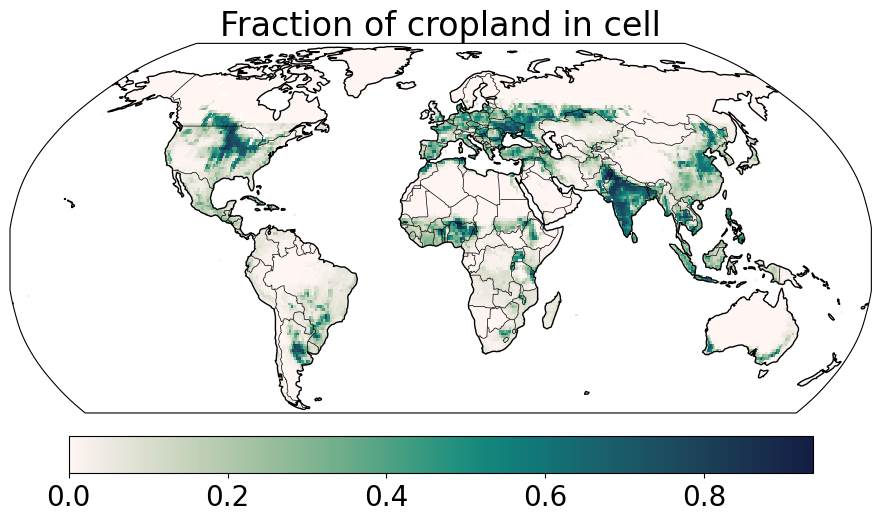

In [12]:
# ---------------------------------
# [ aesthetics ]
# color
mycmap = cmo.cm.tempo
# fonts
fs_title = 24
fs_legend_tick = 20
fs_legend_title= 20 
# extent
lon_min = -181
lon_max = 181
lat_min = -57
lat_max = 86
# ---------------------------------
# --- remove ocean cells
ds['cropland_frac_plot'] = ds['cropland_frac'].where(ds['cropland_area_by_region'] != 0, other=np.nan)

# --- [ PLOT ]
# cropland_frac is a static geographic field — select one slice to get a 2D (lat, lon) array
da = ds['cropland_frac_plot'].isel(scenario=0, crop_fraction=0)

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot (important: specify transform!)
im = da.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),  # data are lat/lon
    cmap= mycmap,
    add_colorbar=True,
    cbar_kwargs={
        "orientation": "horizontal",
        "pad": 0.05,        # distance from plot
        "shrink": 0.8       # optional: make shorter
    }
)
# colorbar text
cbar = im.colorbar
cbar.ax.tick_params(labelsize=fs_legend_tick)
cbar.set_label("", fontsize=fs_legend_title)
# extent + coasts
ax.set_extent([lon_min, lon_max, lat_min, lat_max],
              crs=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
# ax.set_global()
plt.title("Fraction of cropland in cell", fontsize= fs_title)
plt.show()

## Regional mean application rate map across scenarios and crop fractions
Using the fixed regional number across the entire gcam region (no NaNs).

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_68242/1730059321.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


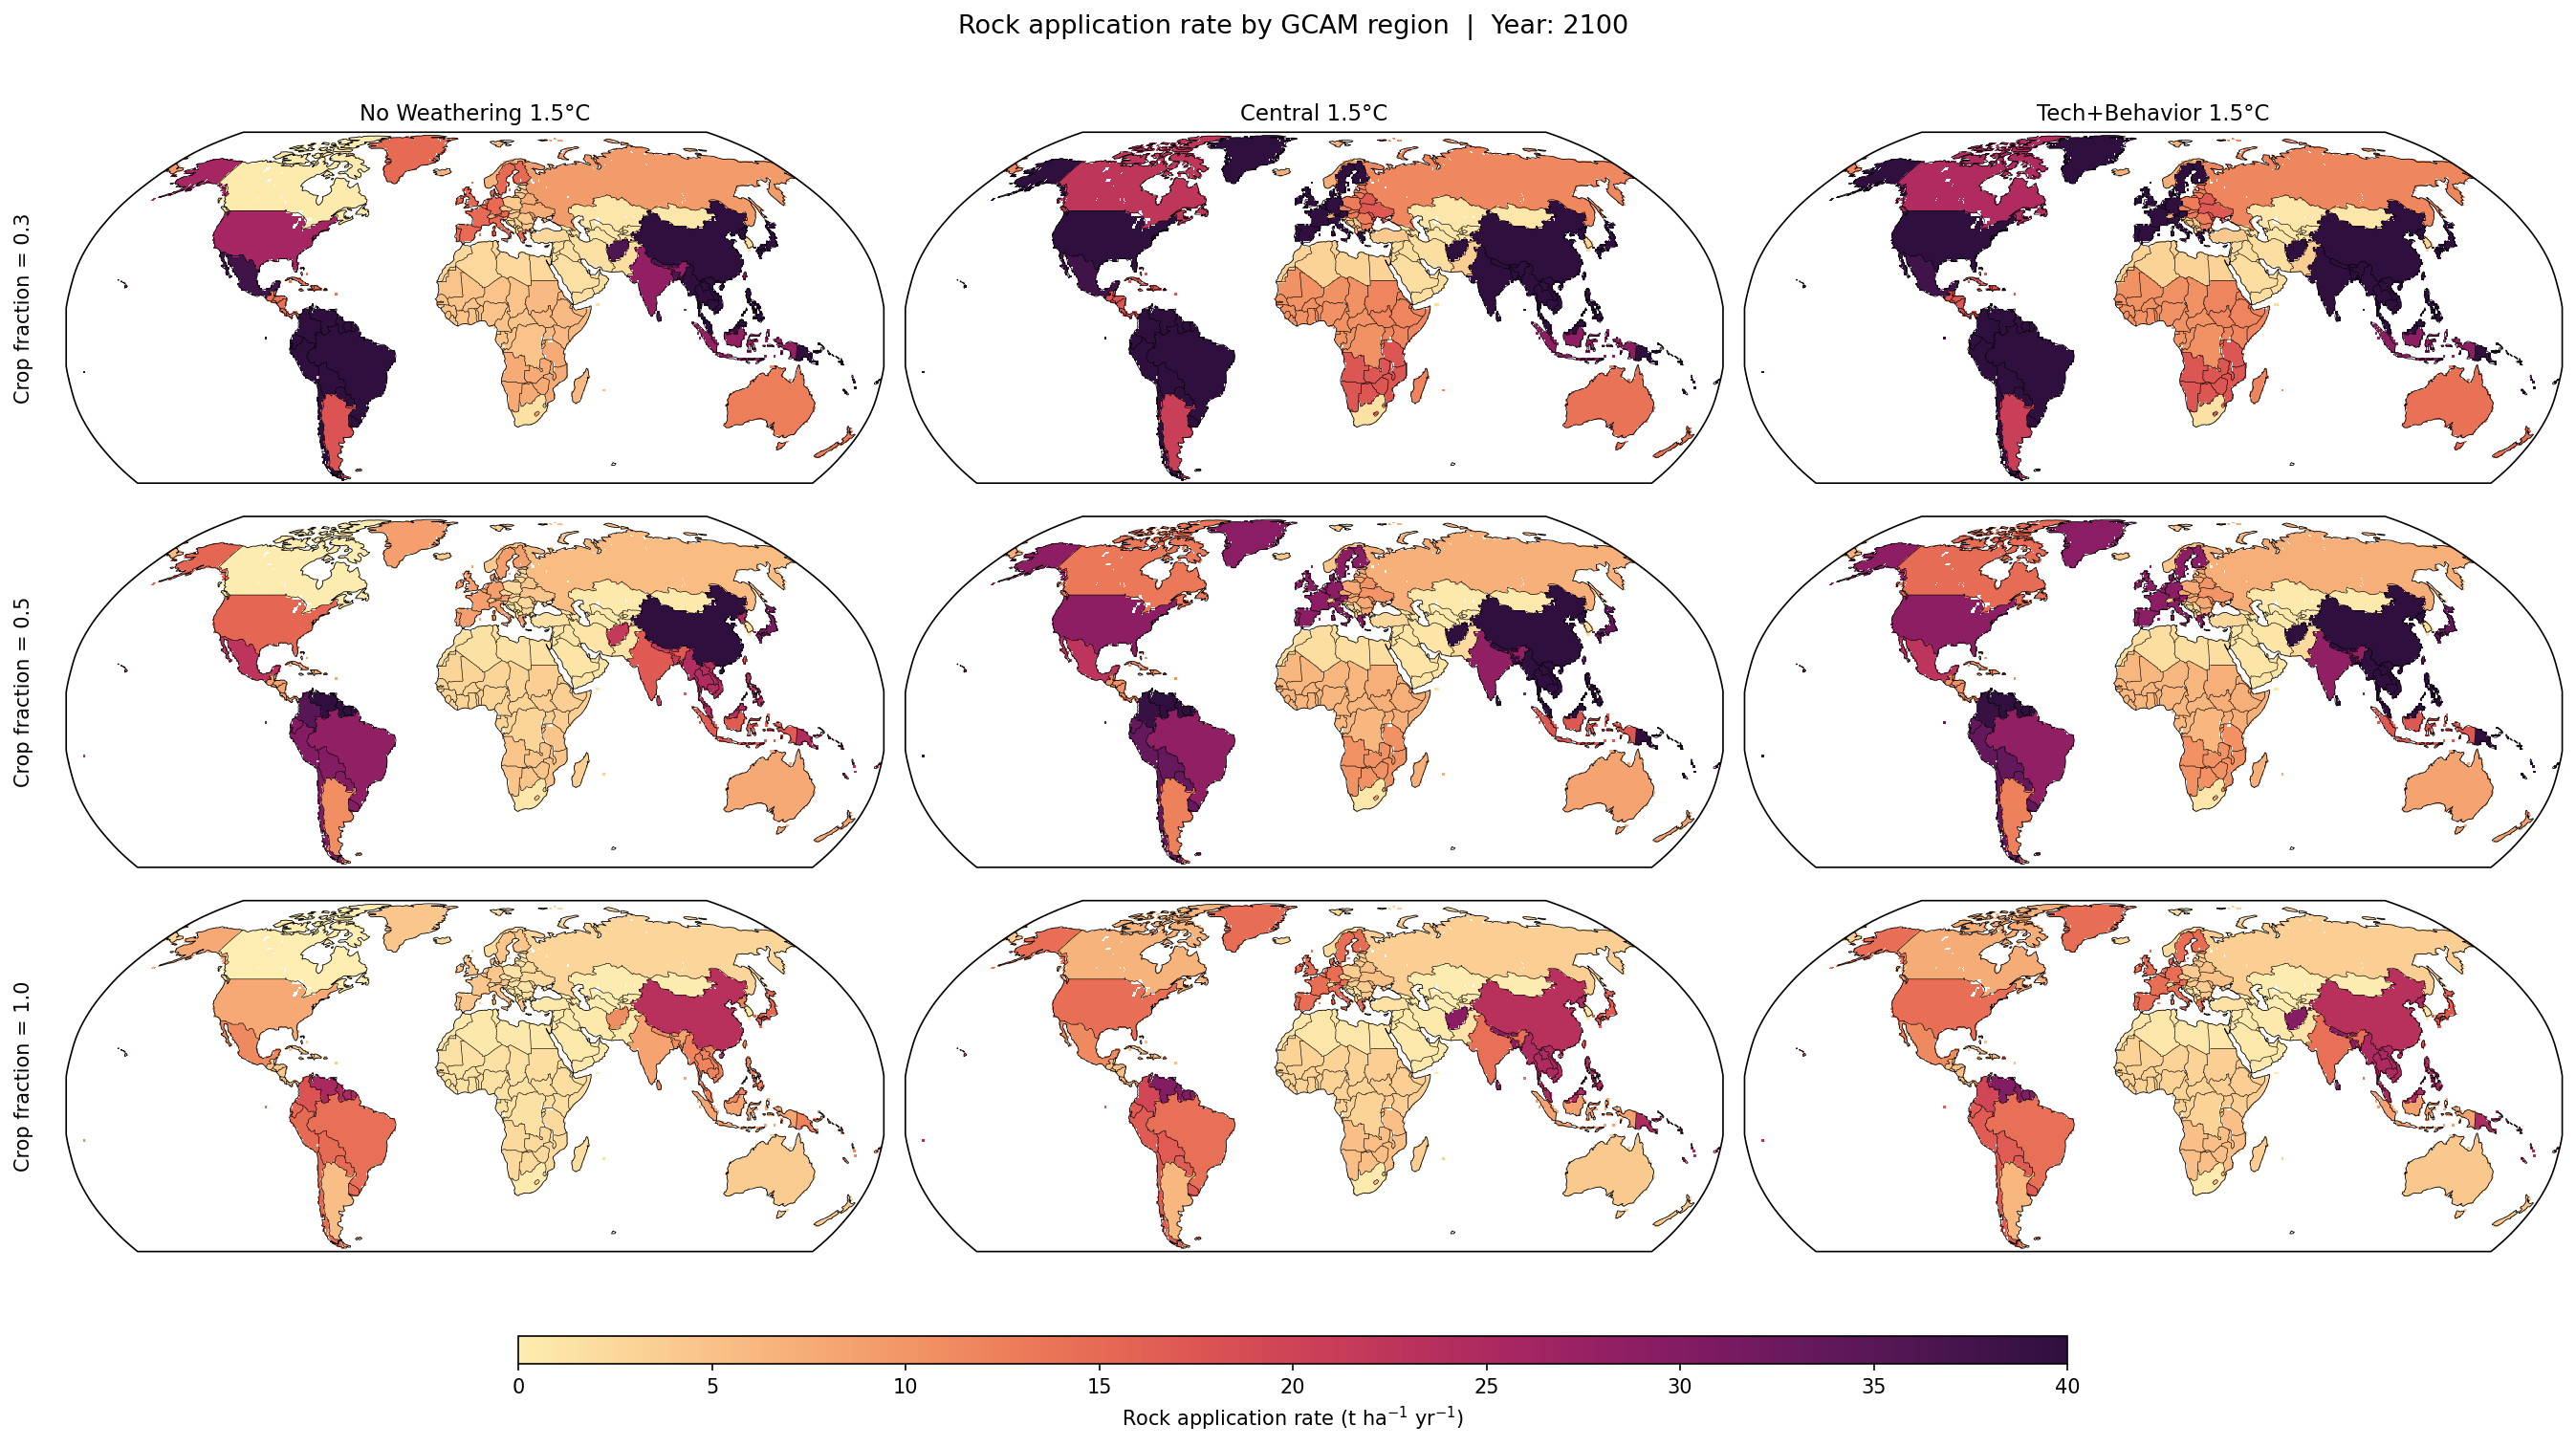

In [37]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
grid_scenarios      = [          # 3 scenarios → 3 columns
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
grid_crop_fractions = [0.3, 0.5, 1.0]   # 3 crop fractions → 3 rows
grid_year           = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_grid  = cmo.cm.matter
vmin_grid    = 0
vmax_grid    = 40
fs_col_title = 11
fs_row_label = 10
fs_cbar_tick = 10
fs_cbar_label= 10
fig_dpi      = 150

lon_min_grid = -181;  lon_max_grid = 181
lat_min_grid =  -57;  lat_max_grid =  86

scen_labels = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ helper: broadcast each region's rockflx_t_ha to all its cells ]
# rockflx_t_ha is NaN outside cropland even though reg_id covers the
# full land area — take the nanmean per region and paint it onto every
# cell sharing that reg_id so the map shows solid regional blocks.
# ============================================================
reg_ids_np  = ds["reg_id"].isel(scenario=0, crop_fraction=0).values  # (y, x)
unique_regs = np.unique(reg_ids_np[reg_ids_np > 0])

def fill_by_region(da):
    vals   = da.values  # (y, x)
    filled = np.full_like(vals, np.nan)
    for reg in unique_regs:
        mask = reg_ids_np == reg
        val  = np.nanmean(vals[mask])
        if np.isfinite(val):
            filled[mask] = val
    return xr.DataArray(filled, dims=["y", "x"], coords={"y": da.y, "x": da.x})

# ============================================================
# [ plot — full GCAM regions (not just cropland cells) ]
# ============================================================
nrows = len(grid_crop_fractions)
ncols = len(grid_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi,
)

for row, cf in enumerate(grid_crop_fractions):
    for col, scen in enumerate(grid_scenarios):
        ax = axes[row, col]

        da_raw = (
            ds["rockflx_t_ha"]
            .sel(scenario=scen, crop_fraction=cf, time=grid_year)
        )
        da = fill_by_region(da_raw)

        da.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_grid,
            vmin=vmin_grid,
            vmax=vmax_grid,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_grid, lon_max_grid, lat_min_grid, lat_max_grid],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels.get(scen, scen), fontsize=fs_col_title, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5, f"Crop fraction = {cf}",
                transform=ax.transAxes,
                fontsize=fs_row_label,
                va="center", ha="right", rotation=90,
            )

# shared colorbar below all panels
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(
    cmap=mycmap_grid,
    norm=mcolors.Normalize(vmin=vmin_grid, vmax=vmax_grid),
)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick)
cbar.set_label(r"Rock application rate (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_cbar_label)

fig.suptitle(f"Rock application rate by GCAM region  |  Year: {grid_year}",
             fontsize=fs_col_title + 2, y=1.01)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Area-scaled rock application rates

`rockflx_t_ha_areaScaled`: for each GCAM region × crop fraction, only the highest-`cropland_frac` cells are selected (sorted descending) until their cumulative `cropland_area` reaches `crop_fraction × total_regional_cropland_area`. All other cells are set to NaN.

In [47]:
# ============================================================
# [ static geographic fields — same across scenario/crop_fraction ]
# ============================================================
_reg_ids_np       = ds["reg_id"].isel(scenario=0, crop_fraction=0).values.astype(int)
_cropland_frac_np = ds["cropland_frac"].isel(scenario=0, crop_fraction=0).values
_cropland_area_np = ds["cropland_area"].isel(scenario=0, crop_fraction=0).values
_cropland_area_by_reg_np = ds["cropland_area_by_region"].isel(scenario=0, crop_fraction=0).values

_unique_regs = np.unique(_reg_ids_np[_reg_ids_np > 0])
_ny, _nx     = _reg_ids_np.shape
_cf_vals     = ds.crop_fraction.values

# ============================================================
# [ build selection mask: (n_cf, ny, nx) ]
# For each crop_fraction, greedily select the highest-cropland_frac
# cells in each region until cumulative cropland_area >= cf × region_total.
# ============================================================
_sel_mask = np.zeros((len(_cf_vals), _ny, _nx), dtype=bool)

for _i, _cf in enumerate(_cf_vals):
    for _reg in _unique_regs:
        _ys, _xs = np.where(_reg_ids_np == _reg)
        if len(_ys) == 0:
            continue

        _region_total = _cropland_area_by_reg_np[_ys[0], _xs[0]]
        if not np.isfinite(_region_total) or _region_total <= 0:
            continue

        _frac_vals = np.nan_to_num(_cropland_frac_np[_ys, _xs], nan=0.0)
        _area_vals = np.nan_to_num(_cropland_area_np[_ys, _xs], nan=0.0)
        _target    = _cf * _region_total

        # sort cells by cropland_frac descending; accumulate cropland_area
        _order   = np.argsort(_frac_vals)[::-1]
        _cumarea = np.cumsum(_area_vals[_order])

        # include up to and including the cell that tips cumarea >= target
        _n = int(np.searchsorted(_cumarea, _target, side="left")) + 1
        _n = min(_n, len(_order))

        _sel = _order[:_n]
        _sel_mask[_i, _ys[_sel], _xs[_sel]] = True

# ============================================================
# [ apply mask → new dataset variable ]
# ============================================================
_sel_da = xr.DataArray(
    _sel_mask,
    dims=["crop_fraction", "y", "x"],
    coords={"crop_fraction": ds.crop_fraction, "y": ds.y, "x": ds.x},
)

ds["rockflx_t_ha_areaScaled"] = ds["rockflx_t_ha"].where(_sel_da)
print("Created ds['rockflx_t_ha_areaScaled']")
ds["rockflx_t_ha_areaScaled"]

Created ds['rockflx_t_ha_areaScaled']


<xarray.DataArray 'rockflx_t_ha_areaScaled' (crop_fraction: 10, scenario: 3,
                                             time: 81, y: 180, x: 360)> Size: 1GB
dask.array<where, shape=(10, 3, 81, 180, 360), dtype=float64, chunksize=(1, 1, 81, 90, 360), chunktype=numpy.ndarray>
Coordinates:
  * crop_fraction  (crop_fraction) float64 80B 0.1 0.2 0.3 0.4 ... 0.8 0.9 1.0
  * scenario       (scenario) object 24B 'exe_central1p5' ... 'exe_techBehavi...
  * time           (time) int64 648B 2020 2021 2022 2023 ... 2097 2098 2099 2100
  * y              (y) float64 1kB 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * x              (x) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
    spatial_ref    int64 8B 0

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_68242/939321068.py:95: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


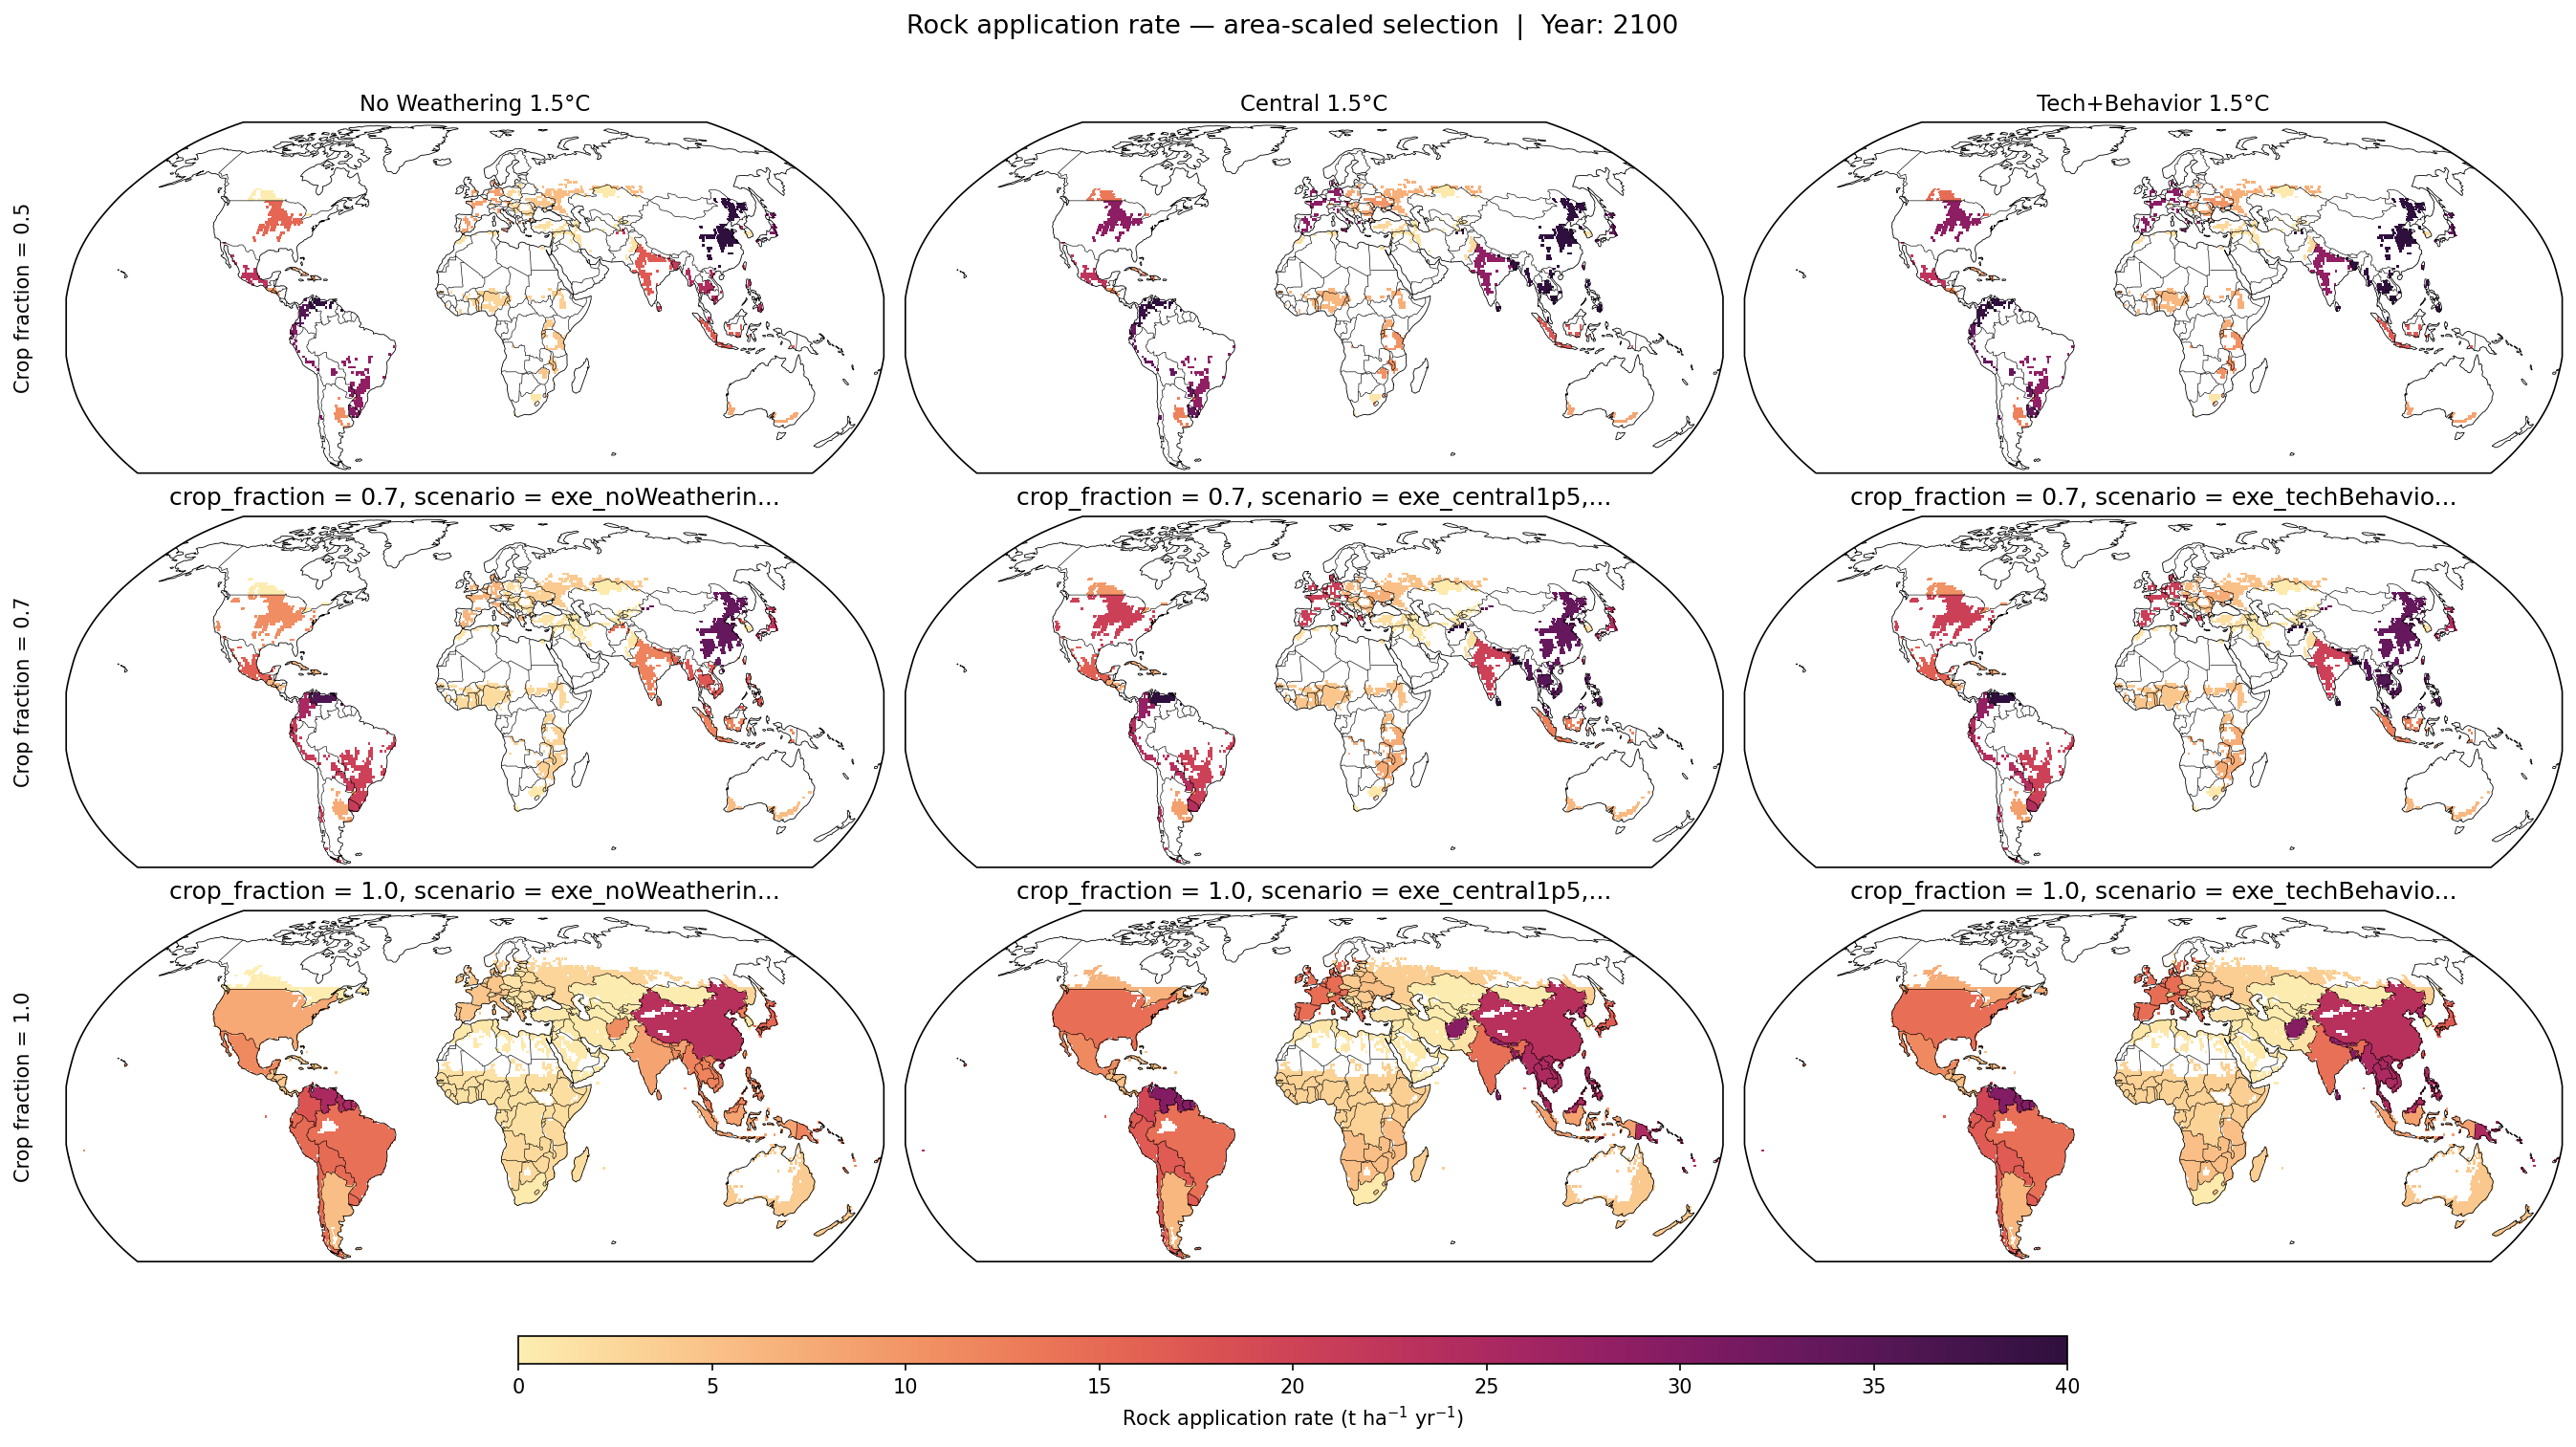

In [50]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
grid_scenarios_as      = [
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
grid_crop_fractions_as = [0.5, 0.7, 1.0]
grid_year_as           = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_as    = cmo.cm.matter
vmin_as      = 0
vmax_as      = 40
fs_col_title_as = 11
fs_row_label_as = 10
fs_cbar_tick_as = 10
fs_cbar_label_as= 10
fig_dpi_as      = 150

lon_min_as = -181;  lon_max_as = 181
lat_min_as =  -57;  lat_max_as =  86

scen_labels_as = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ plot — selected (area-scaled) cropland cells only ]
# ============================================================
nrows = len(grid_crop_fractions_as)
ncols = len(grid_scenarios_as)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi_as,
)

for row, cf in enumerate(grid_crop_fractions_as):
    for col, scen in enumerate(grid_scenarios_as):
        ax = axes[row, col]

        da = (
            ds["rockflx_t_ha_areaScaled"]
            .sel(scenario=scen, crop_fraction=cf, time=grid_year_as)
        )

        da.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_as,
            vmin=vmin_as,
            vmax=vmax_as,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_as, lon_max_as, lat_min_as, lat_max_as],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels_as.get(scen, scen), fontsize=fs_col_title_as, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5, f"Crop fraction = {cf}",
                transform=ax.transAxes,
                fontsize=fs_row_label_as,
                va="center", ha="right", rotation=90,
            )

# shared colorbar
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(
    cmap=mycmap_as,
    norm=mcolors.Normalize(vmin=vmin_as, vmax=vmax_as),
)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick_as)
cbar.set_label(r"Rock application rate (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_cbar_label_as)

fig.suptitle(
    f"Rock application rate — area-scaled selection  |  Year: {grid_year_as}",
    fontsize=fs_col_title_as + 2, y=1.01,
)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Rock application CDFs by global crop area

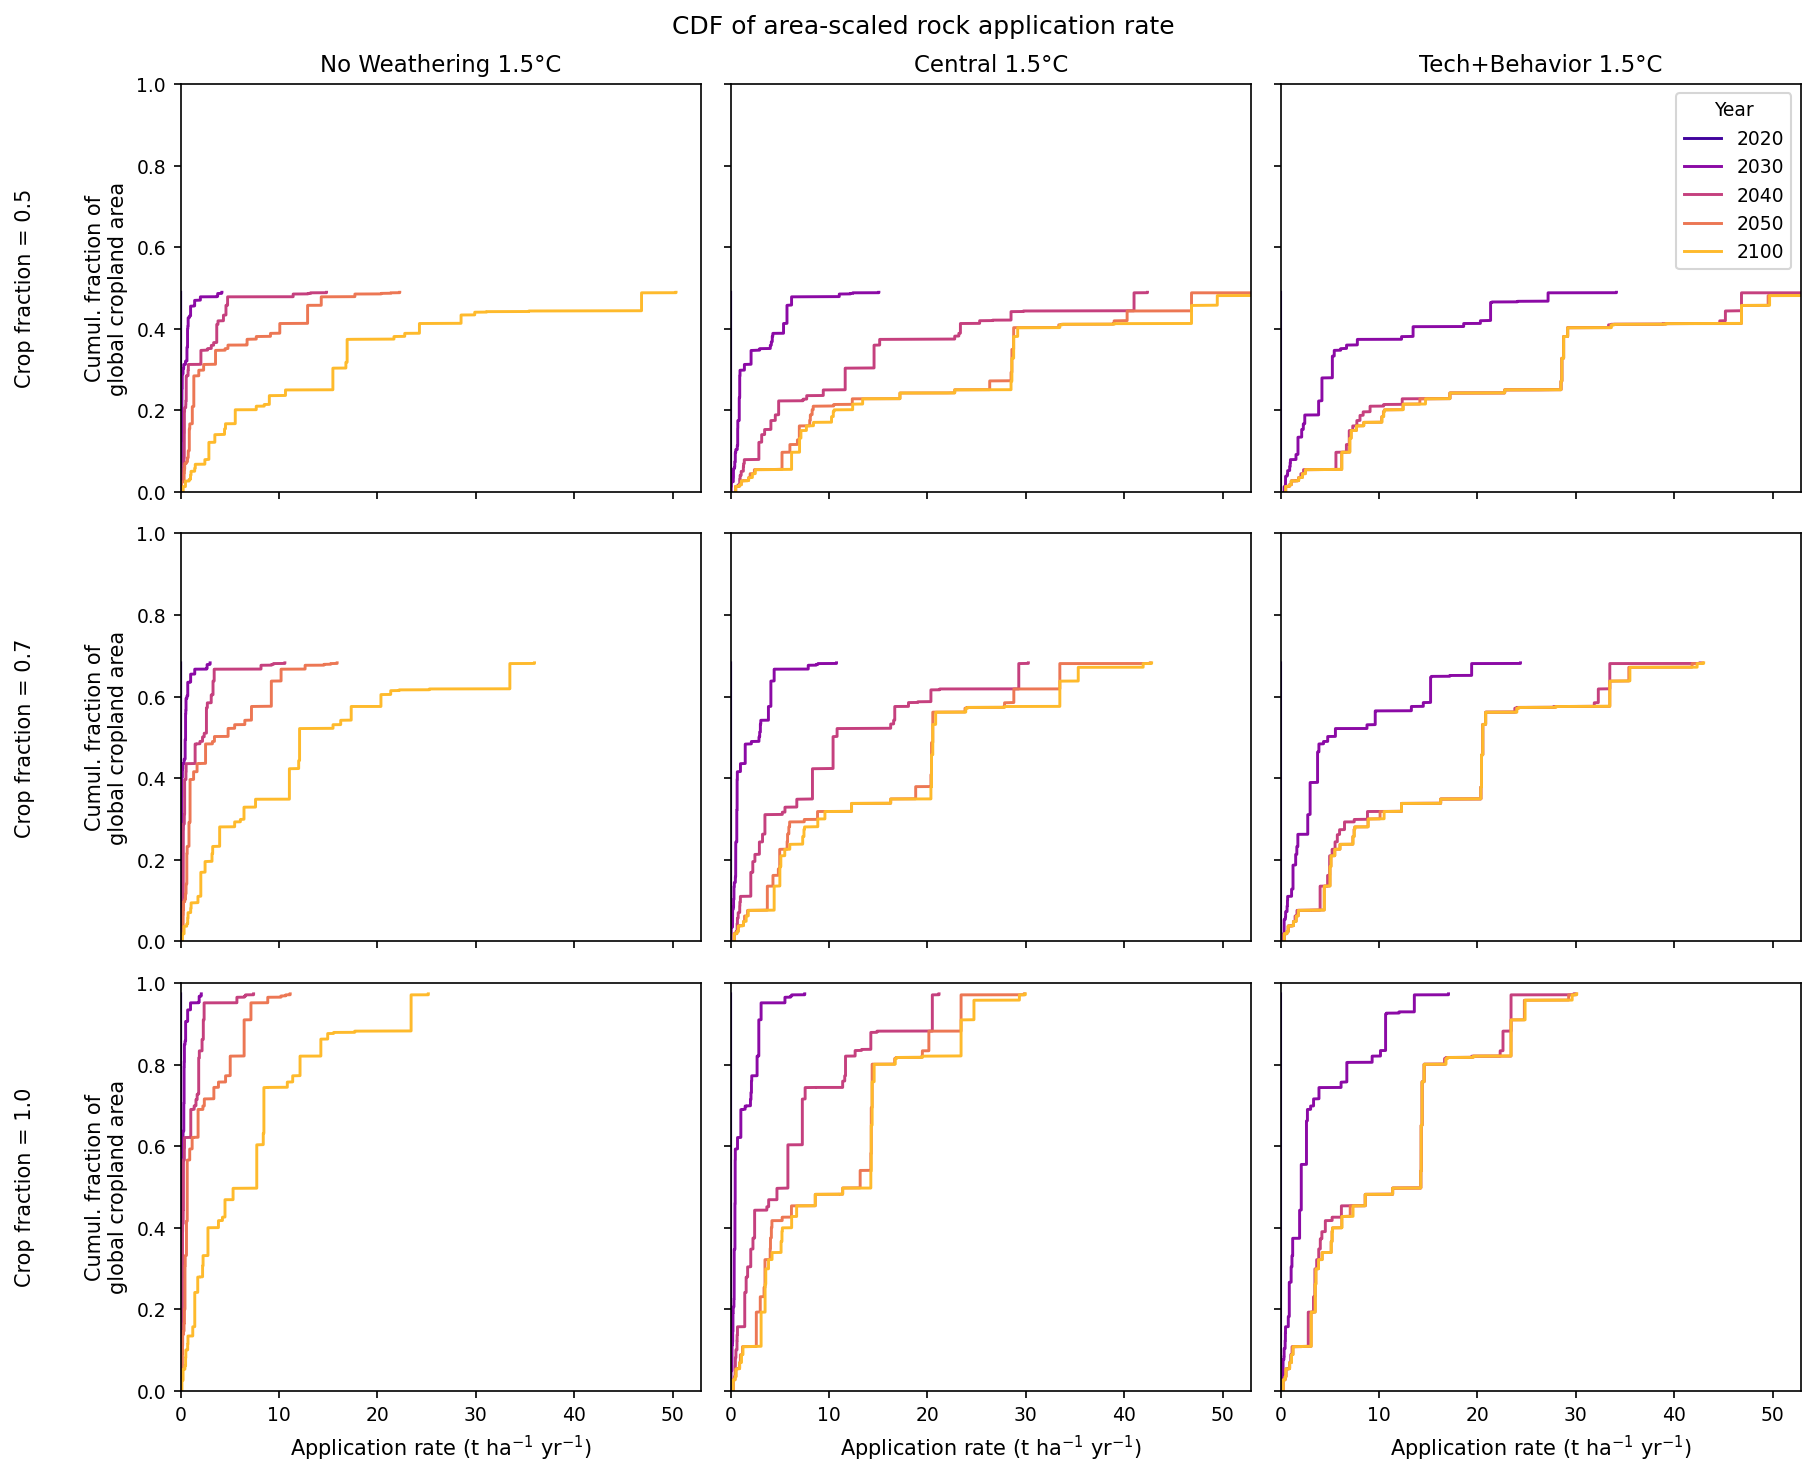

In [55]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
cdf_crop_fractions = [0.5, 0.7, 1.0]   # 3 crop fractions → 3 rows
cdf_scenarios      = [                  # 3 scenarios → 3 columns
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
cdf_years = [2020, 2030, 2040, 2050, 2100]   # one line per year

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
fs_title      = 11
fs_row_label  = 10
fs_axis       = 10
fs_tick       = 9
fs_legend     = 9
fig_dpi       = 150
fig_width     = 12
fig_height    = 10   # taller to accommodate 3 rows

x_min = 0       # set to None for auto
x_max = None

scen_labels_cdf = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ plot ]
# ============================================================
year_colors = plt.cm.plasma(np.linspace(0.1, 0.85, len(cdf_years)))

area_np = ds["cropland_area"].isel(scenario=0, crop_fraction=0).values  # (y, x)
total_global_cropland_area = np.nansum(area_np[np.isfinite(area_np) & (area_np > 0)])

nrows = len(cdf_crop_fractions)
ncols = len(cdf_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(fig_width, fig_height),
    dpi=fig_dpi,
    sharex=True, sharey=True,
)

for row, cf in enumerate(cdf_crop_fractions):
    for col, scen in enumerate(cdf_scenarios):
        ax = axes[row, col]

        for yr, color in zip(cdf_years, year_colors):
            rate = (
                ds["rockflx_t_ha_areaScaled"]
                .sel(scenario=scen, crop_fraction=cf, time=yr)
                .values  # (y, x)
            )

            mask          = np.isfinite(rate) & np.isfinite(area_np) & (area_np > 0)
            rate_valid    = rate[mask]
            area_valid    = area_np[mask]

            sort_idx      = np.argsort(rate_valid)
            rate_sorted   = rate_valid[sort_idx]
            area_sorted   = area_valid[sort_idx]
            cum_area_frac = np.cumsum(area_sorted) / total_global_cropland_area

            ax.plot(rate_sorted, cum_area_frac, color=color, linewidth=1.4,
                    label=str(yr) if (row == 0 and col == ncols - 1) else None)

        ax.set_ylim(0, 1)
        if x_min is not None:
            ax.set_xlim(left=x_min)
        if x_max is not None:
            ax.set_xlim(right=x_max)
        ax.tick_params(labelsize=fs_tick)

        # column headers (top row only)
        if row == 0:
            ax.set_title(scen_labels_cdf.get(scen, scen), fontsize=fs_title, pad=6)

        # x-axis label (bottom row only)
        if row == nrows - 1:
            ax.set_xlabel(r"Application rate (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_axis)

        # y-axis label (left column only)
        if col == 0:
            ax.set_ylabel("Cumul. fraction of\nglobal cropland area", fontsize=fs_axis)

        # row label
        if col == 0:
            ax.annotate(
                f"Crop fraction = {cf}",
                xy=(-0.28, 0.5), xycoords="axes fraction",
                fontsize=fs_row_label, va="center", ha="right", rotation=90,
            )

# legend on top-right panel
handles = [
    plt.Line2D([0], [0], color=c, linewidth=1.4, label=str(yr))
    for yr, c in zip(cdf_years, year_colors)
]
axes[0, -1].legend(handles=handles, title="Year", fontsize=fs_legend,
                   title_fontsize=fs_legend, frameon=True)

fig.suptitle("CDF of area-scaled rock application rate", fontsize=fs_title + 1)
plt.tight_layout()
plt.show()

## Distribution of feedstock application rates

Overlapping histograms of `rockflx_t_ha` (t ha-1 yr-1) across cropland grid cells for a selected scenario and three crop fractions.

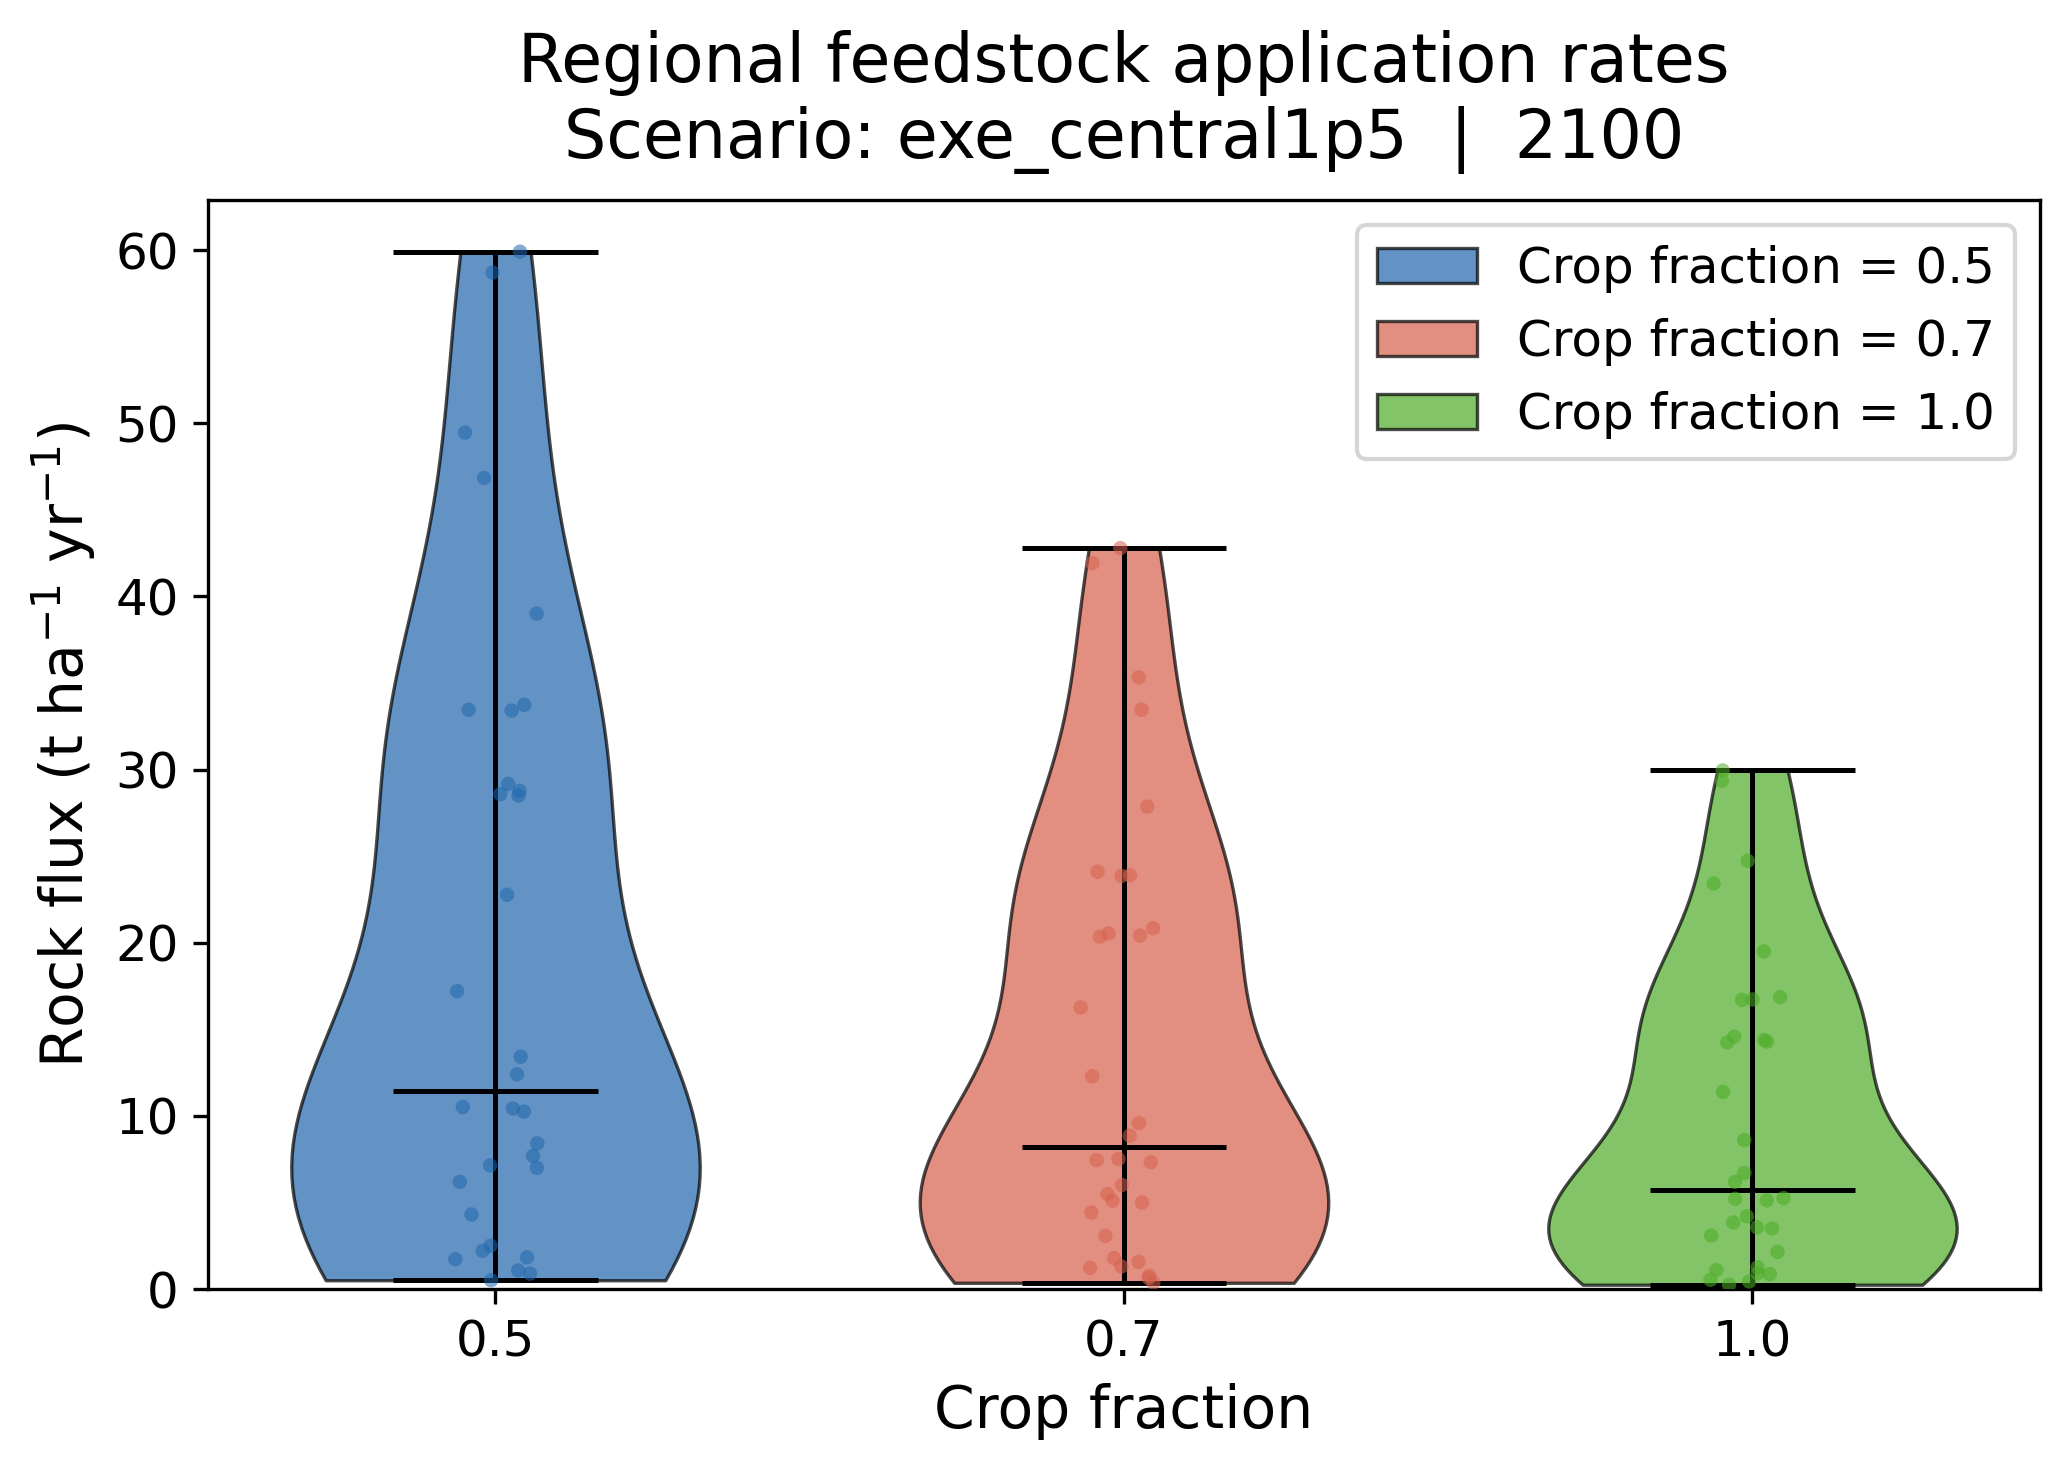

In [ ]:
# ============================================================
# [ aesthetics — edit here ]
# ============================================================
# Font sizes
fs_title      = 16
fs_axis_label = 14
fs_tick       = 12
fs_legend     = 12

# Colors for the three crop-fraction violins (hex or named)
violin_colors = ["#2166ac", "#d6604d", "#4dac26"]
violin_alpha  = 0.7     # fill transparency (0 = invisible, 1 = opaque)
violin_width  = 0.65    # width of each violin body

# Median / extrema lines inside the violin
show_median   = True
line_color    = "black"
line_width    = 1.2

# Individual GCAM region data points overlaid on violins
show_points   = True    # set False to hide individual points
point_alpha   = 0.55
point_size    = 12      # marker area in pt²
point_jitter  = 0.07    # max horizontal jitter (keeps points inside violin)

# Figure
fig_width  = 7
fig_height = 5
fig_dpi    = 300        # 300 dpi for publication

# Optional y-axis limits (None = auto)
y_min = 0
y_max = None

# ============================================================
# [ user selections — edit here ]
# ============================================================
selected_scenario       = "exe_central1p5"  # one of: scenarios
selected_crop_fractions = [0.5, 0.7, 1.0]  # three values from: crop_fractions
selected_year           = 2100  # int year (e.g. 2050), or None to use all years

# ============================================================
# [ aggregate rockflx_t_ha to GCAM regional means ]
# Each data point in the violin = one GCAM region (× one year if all years are used)
# This removes the grid-cell-count-by-area artifact.
# ============================================================
# reg_id is geographically fixed — grab one spatial slice
reg_ids = ds["reg_id"].isel(scenario=0, crop_fraction=0).values   # (y, x) int array
unique_regions = np.unique(reg_ids)
unique_regions = unique_regions[unique_regions > 0]               # drop 0 = ocean / no region

da_scen = ds["rockflx_t_ha"].sel(scenario=selected_scenario)
if selected_year is not None:
    da_scen = da_scen.sel(time=selected_year)   # → (crop_fraction, y, x)
    time_label = str(selected_year)
else:
    time_label = "all years"

da_scen = da_scen.load()  # compute dask array into memory

violin_data = []
for cf in selected_crop_fractions:
    da_cf = da_scen.sel(crop_fraction=cf).values  # (y, x) or (time, y, x)
    regional_vals = []
    for reg in unique_regions:
        mask = reg_ids == reg   # bool (y, x)
        if selected_year is not None:
            # one spatial mean per region for the chosen year
            val = float(np.nanmean(da_cf[mask]))
            if np.isfinite(val) and val > 0:
                regional_vals.append(val)
        else:
            # spatial mean per region per year → (n_time,) values
            vals = np.nanmean(da_cf[:, mask], axis=1)
            vals = vals[np.isfinite(vals) & (vals > 0)]
            regional_vals.extend(vals.tolist())
    violin_data.append(regional_vals)

# ============================================================
# [ plot ]
# ============================================================
rng = np.random.default_rng(42)   # reproducible jitter
positions = np.arange(1, len(selected_crop_fractions) + 1)

fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=fig_dpi)

parts = ax.violinplot(
    violin_data,
    positions=positions,
    widths=violin_width,
    showmedians=show_median,
    showextrema=True,
)

# style violin bodies
for pc, color in zip(parts["bodies"], violin_colors):
    pc.set_facecolor(color)
    pc.set_alpha(violin_alpha)
    pc.set_edgecolor(line_color)
    pc.set_linewidth(0.8)

# style median and range lines
for key in ("cmedians", "cmins", "cmaxes", "cbars"):
    parts[key].set_edgecolor(line_color)
    parts[key].set_linewidth(line_width)

# overlay individual region (× year) data points with jitter
if show_points:
    for vals, pos, color in zip(violin_data, positions, violin_colors):
        jitter = rng.uniform(-point_jitter, point_jitter, size=len(vals))
        ax.scatter(
            pos + jitter, vals,
            color=color, alpha=point_alpha, s=point_size,
            zorder=3, edgecolors="none",
        )

# axes
ax.set_xticks(positions)
ax.set_xticklabels([str(cf) for cf in selected_crop_fractions], fontsize=fs_tick)
ax.set_xlabel("Crop fraction", fontsize=fs_axis_label)
ax.set_ylabel(r"Rock flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_axis_label)
ax.set_title(
    f"Regional feedstock application rates\n"
    f"Scenario: {selected_scenario}  |  {time_label}",
    fontsize=fs_title, pad=10,
)
ax.tick_params(axis="both", labelsize=fs_tick)

if y_min is not None:
    ax.set_ylim(bottom=y_min)
if y_max is not None:
    ax.set_ylim(top=y_max)

# legend
legend_handles = [
    mpatches.Patch(facecolor=c, alpha=violin_alpha, edgecolor=line_color,
                   linewidth=0.8, label=f"Crop fraction = {cf}")
    for c, cf in zip(violin_colors, selected_crop_fractions)
]
ax.legend(handles=legend_handles, fontsize=fs_legend, frameon=True)

plt.tight_layout()
plt.savefig(f"violin_rockflx_{selected_scenario}_{time_label}.png", dpi=fig_dpi, bbox_inches="tight")
plt.show()

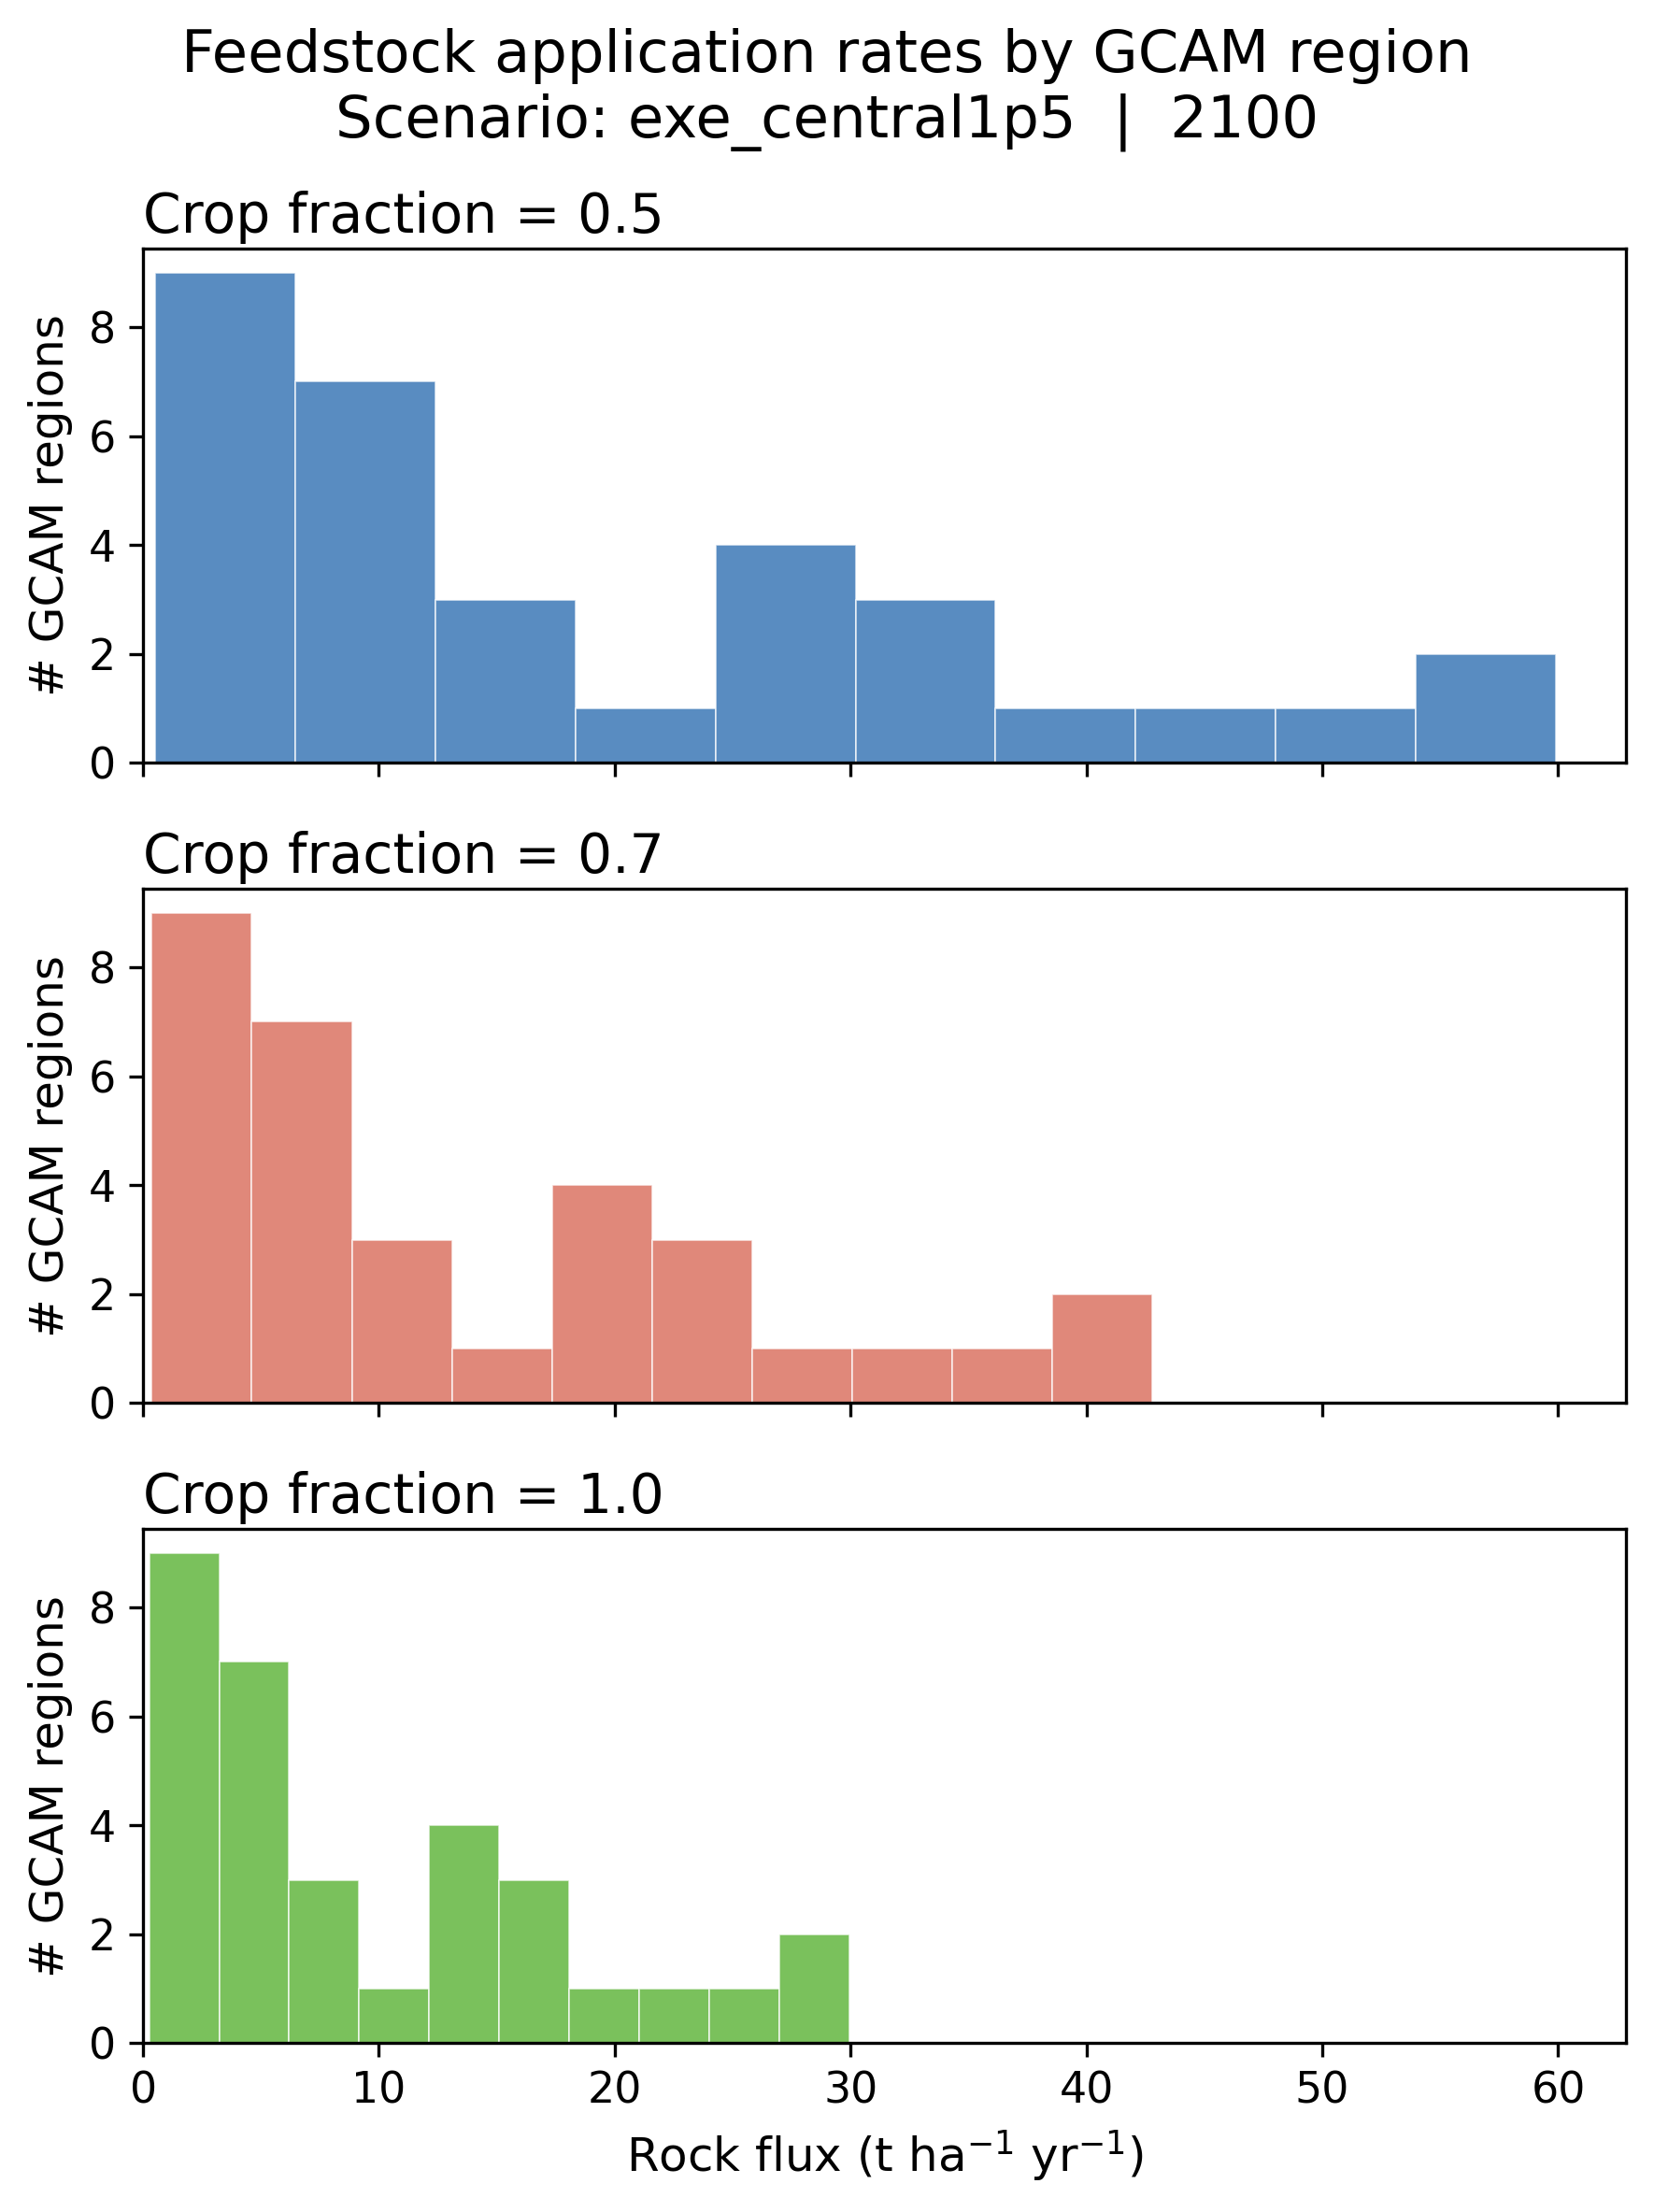

In [21]:
# ============================================================
# [ aesthetics — edit here ]
# ============================================================
fs_title       = 14
fs_axis_label  = 12
fs_tick        = 11

hist_colors    = ["#2166ac", "#d6604d", "#4dac26"]  # one per crop fraction
hist_alpha     = 0.75
hist_edgecolor = "white"
hist_linewidth = 0.4
hist_n_bins    = 10

fig_width  = 6
fig_height = 8
fig_dpi    = 300

# Optional x-axis limits (None = auto)
x_min = 0
x_max = None

# ============================================================
# [ user selections — edit here ]
# ============================================================
selected_scenario       = "exe_central1p5"  # one of: scenarios
selected_crop_fractions = [0.5, 0.7, 1.0]  # three values from: crop_fractions
selected_year           = 2100              # int year — a single year keeps y-axis as "# GCAM regions"

# ============================================================
# [ aggregate rockflx_t_ha to GCAM regional means ]
# reg_ids and unique_regions are defined in the violin plot cell above
# ============================================================
da_scen_h = ds["rockflx_t_ha"].sel(scenario=selected_scenario).sel(time=selected_year).load()
time_label_h = str(selected_year)

hist_data = []
for cf in selected_crop_fractions:
    da_cf = da_scen_h.sel(crop_fraction=cf).values   # (y, x)
    regional_vals = []
    for reg in unique_regions:
        mask = reg_ids == reg
        val = float(np.nanmean(da_cf[mask]))
        if np.isfinite(val) and val > 0:
            regional_vals.append(val)
    hist_data.append(regional_vals)

# ============================================================
# [ plot — three stacked subplots, one per crop fraction ]
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(fig_width, fig_height), dpi=fig_dpi, sharex=True)

for ax, vals, cf, color in zip(axes, hist_data, selected_crop_fractions, hist_colors):
    ax.hist(
        vals,
        bins=hist_n_bins,
        color=color,
        alpha=hist_alpha,
        edgecolor=hist_edgecolor,
        linewidth=hist_linewidth,
    )
    ax.set_ylabel("# GCAM regions", fontsize=fs_axis_label)
    ax.tick_params(axis="both", labelsize=fs_tick)
    ax.set_title(f"Crop fraction = {cf}", fontsize=fs_title, loc="left", pad=4)
    if x_min is not None:
        ax.set_xlim(left=x_min)
    if x_max is not None:
        ax.set_xlim(right=x_max)

axes[-1].set_xlabel(r"Rock flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_axis_label)
fig.suptitle(
    f"Feedstock application rates by GCAM region\n"
    f"Scenario: {selected_scenario}  |  {time_label_h}",
    fontsize=fs_title + 1,
)

plt.tight_layout()
plt.show()

# SCRATCH -------------------

## Assuming the constant application amount case
If we prescribe an application amount, calculate the area of rock application for each region and each time slice. Get a sense for a minimum application amount that we can allow before we need more than 100\% crop area in a region.

## Alternative: fixed application rate

Instead of distributing a fixed total mass over a fixed area, fix the application rate (t/ha/yr) and compute the area required per region to achieve the GCAM-derived `rockflx_Mt` targets. Also normalize that area to total regional cropland to get the fraction of cropland that would need to be treated.

Note: `rockflx_Mt` does not vary with `crop_fraction` (crop fraction only scales the t/ha denominator), so the new variables have dims `(scenario, time, reg_id, fixed_rockflx_t_ha_yr)`.

In [57]:
fixed_rates = np.array([1, 5, 10, 20, 40, 60], dtype=float)  # [t/ha/yr]

# -- reg_id grid (geographically fixed; same across crop_fraction and scenario)
reg_id_np = ds["reg_id"].isel(crop_fraction=0, scenario=0).values  # (y, x)
reg_id_flat = reg_id_np.flatten()
unique_regs = np.sort(np.unique(reg_id_flat[reg_id_flat > 0]))

# -- total cropland per region [ha]
# cropland_area_by_region is a constant per region painted onto every pixel in that region
carb_flat = ds["cropland_area_by_region"].isel(crop_fraction=0, scenario=0).values.flatten()
total_cropland_ha = np.array([
    float(np.nanmean(carb_flat[reg_id_flat == rid])) / 1e4  # m2 → ha
    for rid in unique_regs
])
total_cropland_ha_da = xr.DataArray(
    total_cropland_ha,
    coords={"reg_id": unique_regs},
    dims="reg_id"
)

# -- total regional rockflx_Mt [Mt/yr] per scenario and time
# rockflx_Mt is the same across crop_fraction, so drop that dim
# sum over all pixels in each region to recover the regional total
rockflx_4d = ds["rockflx_Mt"].isel(crop_fraction=0).values  # (scenario, time, y, x)
rockflx_flat = rockflx_4d.reshape(*rockflx_4d.shape[:2], -1)  # (scenario, time, n_pixels)

regional_Mt = np.zeros((len(ds.scenario), len(ds.time), len(unique_regs)))
for i, rid in enumerate(unique_regs):
    mask = reg_id_flat == rid
    regional_Mt[:, :, i] = np.nansum(rockflx_flat[:, :, mask], axis=-1)

regional_Mt_da = xr.DataArray(
    regional_Mt,
    coords={"scenario": ds.scenario, "time": ds.time, "reg_id": unique_regs},
    dims=("scenario", "time", "reg_id")
)

# -- fixed rate as a named coordinate dimension
fixed_rates_da = xr.DataArray(
    fixed_rates,
    coords={"fixed_rockflx_t_ha_yr": fixed_rates},
    dims="fixed_rockflx_t_ha_yr"
)

# -- area required to achieve the regional rockflx_Mt target at each fixed rate
# [Mt * 1e6 t/Mt] / [t/ha] = ha
# xarray broadcasting → dims: (scenario, time, reg_id, fixed_rockflx_t_ha_yr)
area_required_ha = (regional_Mt_da * 1e6) / fixed_rates_da

# -- fraction of total regional cropland required
frac_cropland_required = area_required_ha / total_cropland_ha_da

# -- assemble into a dataset
ds_fixed_rate = xr.Dataset({
    "area_required_ha": area_required_ha,
    "frac_cropland_required": frac_cropland_required,
})
ds_fixed_rate

<xarray.Dataset> Size: 747kB
Dimensions:                 (scenario: 3, time: 81, reg_id: 32,
                             fixed_rockflx_t_ha_yr: 6)
Coordinates:
  * scenario                (scenario) object 24B 'exe_central1p5' ... 'exe_t...
  * time                    (time) int64 648B 2020 2021 2022 ... 2098 2099 2100
  * reg_id                  (reg_id) int32 128B 1 2 3 4 5 6 ... 28 29 30 31 32
  * fixed_rockflx_t_ha_yr   (fixed_rockflx_t_ha_yr) float64 48B 1.0 5.0 ... 60.0
Data variables:
    area_required_ha        (scenario, time, reg_id, fixed_rockflx_t_ha_yr) float64 373kB ...
    frac_cropland_required  (scenario, time, reg_id, fixed_rockflx_t_ha_yr) float64 373kB ...

### Map: fraction of cropland required at fixed application rates

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_68242/704725172.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


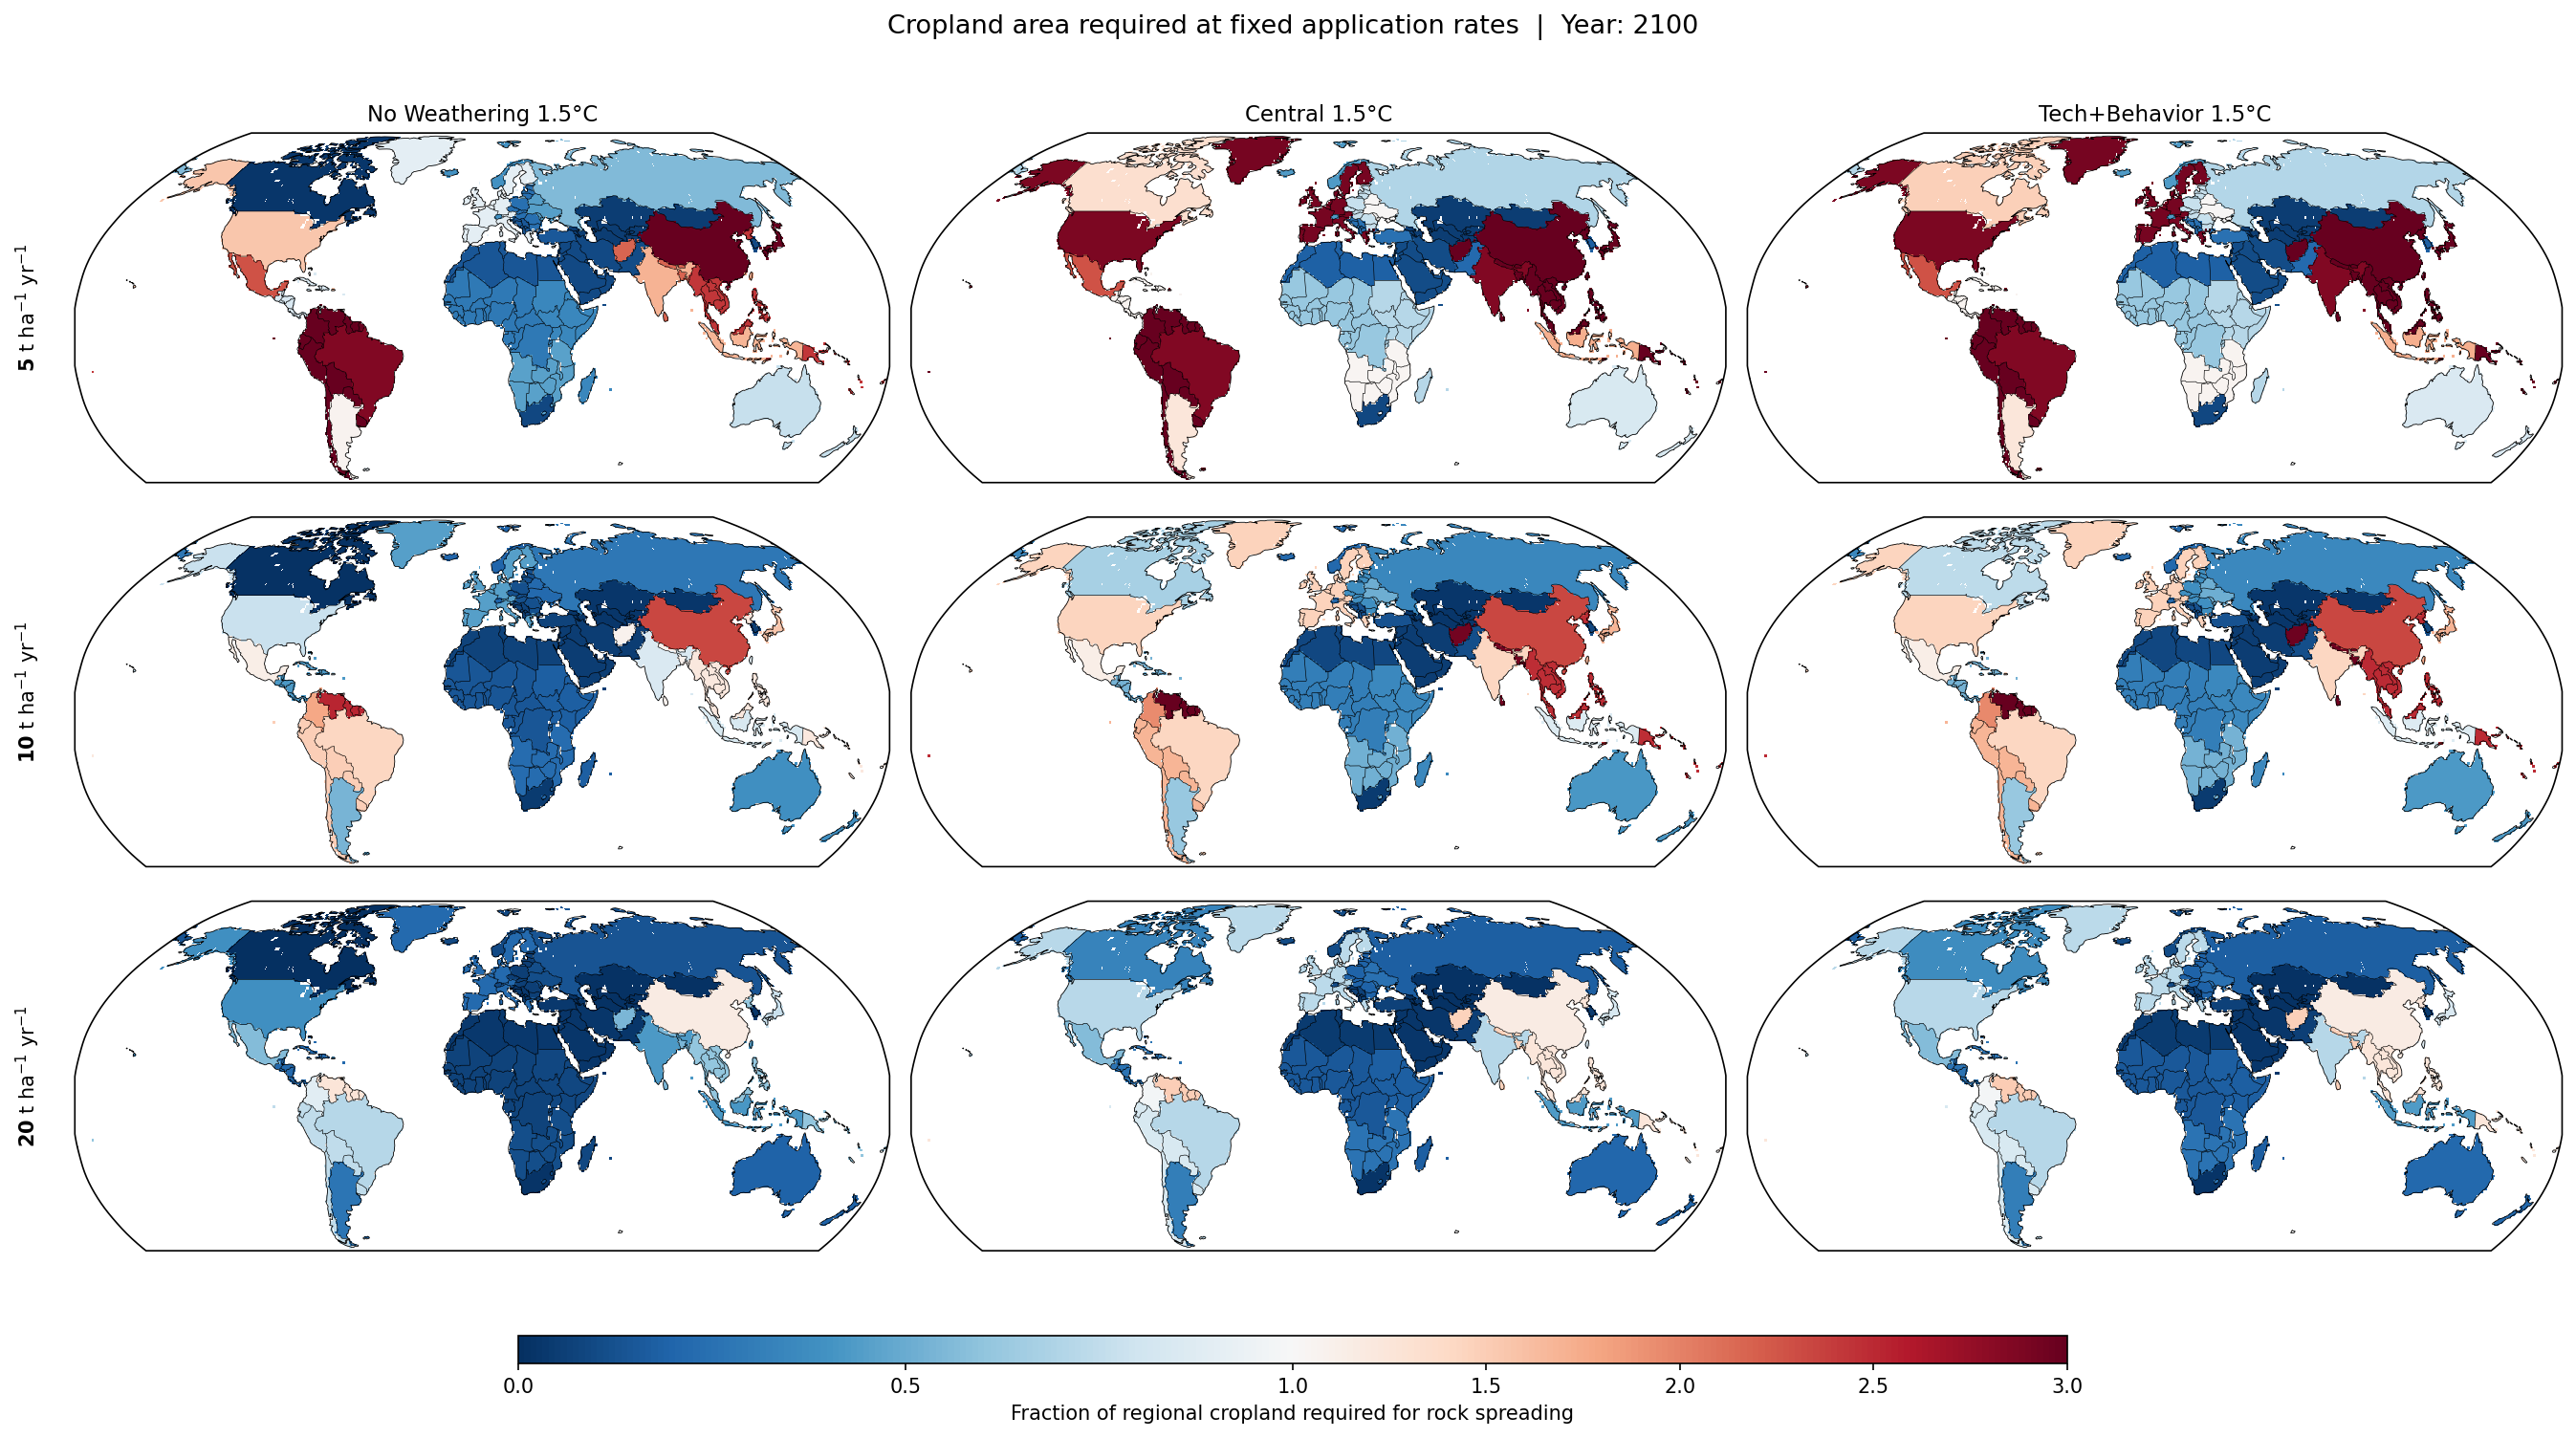

In [63]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
map_scenarios    = [
    "exe_noWeathering1p5",
    "exe_central1p5",
    "exe_techBehaviorChange1p5",
]
map_fixed_rates  = [5, 10, 20]   # three values from fixed_rates
map_year         = 2100

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
mycmap_frac  = "RdBu_r"   # diverging; blue < 1, red > 1
vmin_frac    = 0.0
vcenter_frac = 1.0         # colorbar center = 100% cropland required
vmax_frac    = 3.0         # regions above this are clipped to the same red

fs_col_title  = 11
fs_row_label  = 10
fs_cbar_tick  = 10
fs_cbar_label = 10
fig_dpi       = 150

lon_min_frac = -181;  lon_max_frac = 181
lat_min_frac =  -57;  lat_max_frac =  86

scen_labels_frac = {
    "exe_central1p5":            "Central 1.5°C",
    "exe_noWeathering1p5":       "No Weathering 1.5°C",
    "exe_techBehaviorChange1p5": "Tech+Behavior 1.5°C",
}

# ============================================================
# [ helper: paint per-region scalar values onto the 2D pixel grid ]
# ============================================================
def paint_regions(values_by_regid, reg_id_grid):
    out = np.full(reg_id_grid.shape, np.nan)
    for rid, val in values_by_regid.items():
        out[reg_id_grid == rid] = val
    return out

# ============================================================
# [ plot — rows = fixed rate, cols = scenario ]
# ============================================================
norm_frac = mcolors.TwoSlopeNorm(vmin=vmin_frac, vcenter=vcenter_frac, vmax=vmax_frac)

nrows = len(map_fixed_rates)
ncols = len(map_scenarios)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(6 * ncols, 3.2 * nrows),
    subplot_kw={"projection": ccrs.Robinson()},
    dpi=fig_dpi,
)

for row, rate in enumerate(map_fixed_rates):
    for col, scen in enumerate(map_scenarios):
        ax = axes[row, col]

        frac_vals = (
            ds_fixed_rate["frac_cropland_required"]
            .sel(scenario=scen, time=map_year, fixed_rockflx_t_ha_yr=rate)
            .values  # (reg_id,)
        )

        painted = paint_regions(dict(zip(unique_regs, frac_vals)), reg_id_np)
        painted_da = xr.DataArray(painted, dims=["y", "x"],
                                  coords={"y": ds.y, "x": ds.x})

        painted_da.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap=mycmap_frac,
            norm=norm_frac,
            add_colorbar=False,
        )

        ax.set_extent([lon_min_frac, lon_max_frac, lat_min_frac, lat_max_frac],
                      crs=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)

        if row == 0:
            ax.set_title(scen_labels_frac.get(scen, scen), fontsize=fs_col_title, pad=6)

        if col == 0:
            ax.text(
                -0.04, 0.5,
                r"$\bf{" + str(int(rate)) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                transform=ax.transAxes,
                fontsize=fs_row_label,
                va="center", ha="right", rotation=90,
            )

# shared colorbar
cbar_ax = fig.add_axes([0.2, 0.03, 0.6, 0.02])
sm = plt.cm.ScalarMappable(cmap=mycmap_frac, norm=norm_frac)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
cbar.ax.tick_params(labelsize=fs_cbar_tick)
cbar.set_label("Fraction of regional cropland required for rock spreading",
               fontsize=fs_cbar_label)

fig.suptitle(
    f"Cropland area required at fixed application rates  |  Year: {map_year}",
    fontsize=fs_col_title + 2, y=1.01,
)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### Time series: fraction of cropland required per region at fixed application rates

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_68242/4007470408.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_regions = plt.cm.get_cmap("tab20", len(unique_regs))


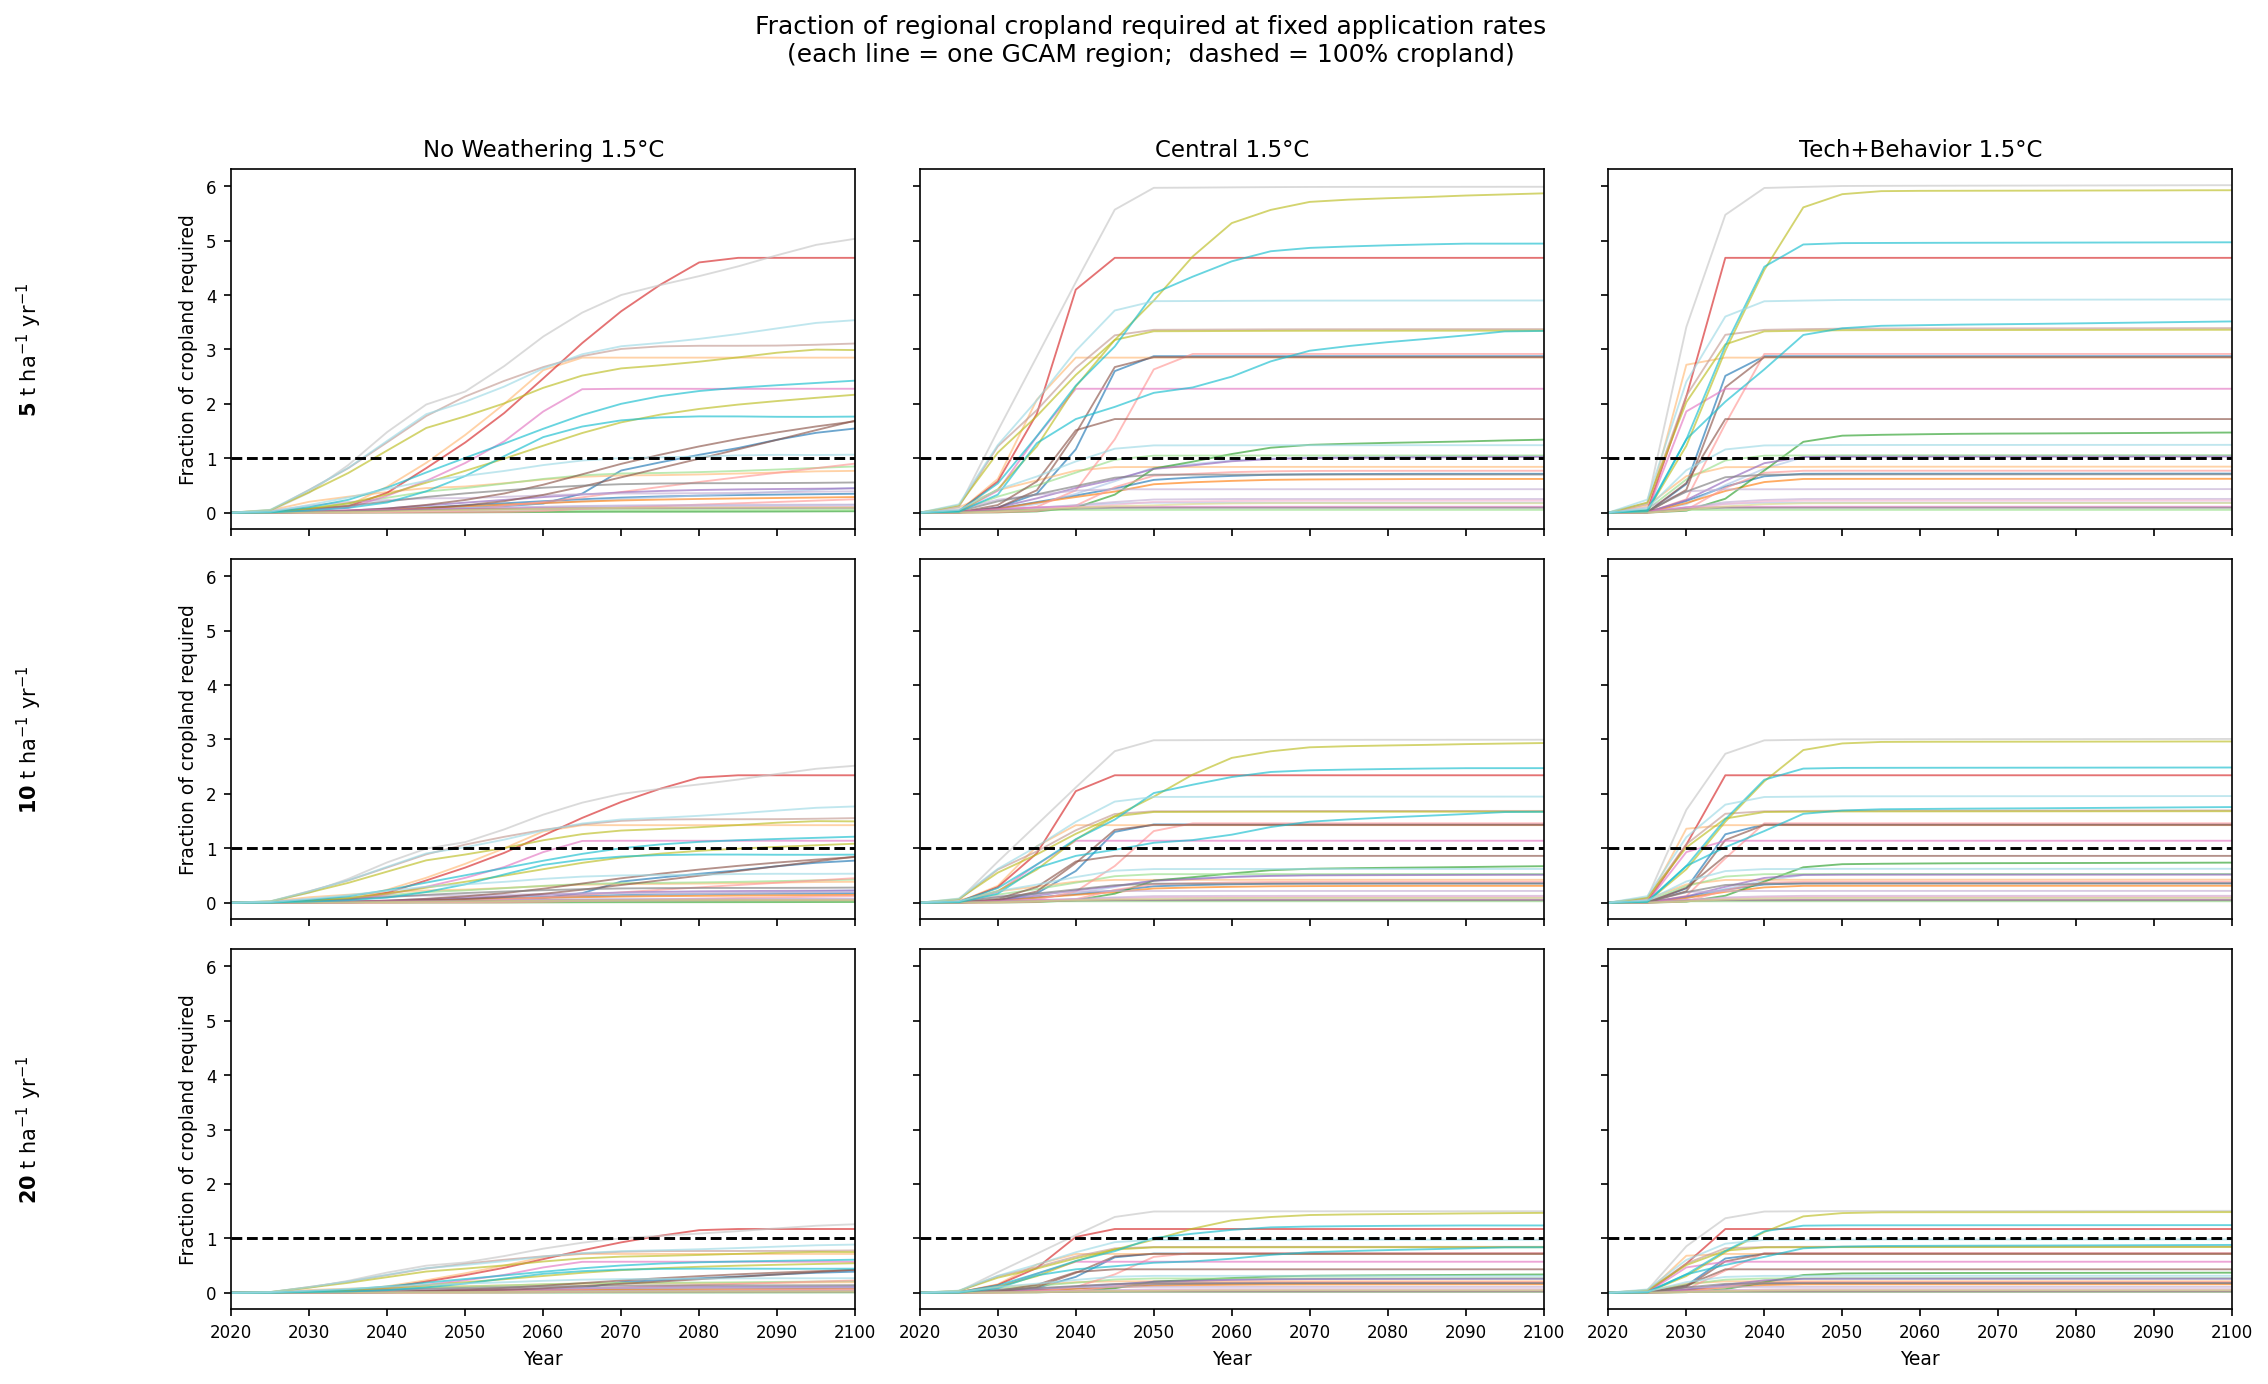

In [64]:
# ============================================================
# [ user selections — edit here ]
# ============================================================
ts_scenarios   = map_scenarios    # reuse from map cell above
ts_fixed_rates = map_fixed_rates  # reuse from map cell above

# ============================================================
# [ aesthetics — edit here ]
# ============================================================
cmap_regions = plt.cm.get_cmap("tab20", len(unique_regs))
lw_region    = 0.9
alpha_region = 0.65
hline_color  = "black"
hline_lw     = 1.4
hline_ls     = "--"

fs_col_title = 11
fs_row_label = 10
fs_axis      = 9
fs_tick      = 8
fig_dpi      = 150

# ============================================================
# [ plot — rows = fixed rate, cols = scenario ]
# ============================================================
nrows = len(ts_fixed_rates)
ncols = len(ts_scenarios)
times = ds_fixed_rate.time.values

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 3 * nrows),
    dpi=fig_dpi,
    sharex=True, sharey=True,
)

for row, rate in enumerate(ts_fixed_rates):
    for col, scen in enumerate(ts_scenarios):
        ax = axes[row, col]

        # frac_cropland_required for this scenario + rate: (time, reg_id)
        da = (
            ds_fixed_rate["frac_cropland_required"]
            .sel(scenario=scen, fixed_rockflx_t_ha_yr=rate)
        )

        for i, rid in enumerate(unique_regs):
            ax.plot(times, da.sel(reg_id=rid).values,
                    color=cmap_regions(i), lw=lw_region, alpha=alpha_region)

        # 100% cropland threshold
        ax.axhline(1.0, color=hline_color, lw=hline_lw, ls=hline_ls, zorder=5)

        ax.set_xlim(times[0], times[-1])
        ax.tick_params(labelsize=fs_tick)

        # column headers (top row only)
        if row == 0:
            ax.set_title(scen_labels_frac.get(scen, scen),
                         fontsize=fs_col_title, pad=6)

        # x-axis label (bottom row only)
        if row == nrows - 1:
            ax.set_xlabel("Year", fontsize=fs_axis)

        # row label + y-axis label (left column only)
        if col == 0:
            ax.set_ylabel("Fraction of cropland required", fontsize=fs_axis)
            ax.text(
                -0.3, 0.5,
                r"$\bf{" + str(int(rate)) + r"}$ t ha$^{-1}$ yr$^{-1}$",
                transform=ax.transAxes,
                fontsize=fs_row_label,
                va="center", ha="right", rotation=90,
            )

fig.suptitle(
    "Fraction of regional cropland required at fixed application rates\n"
    "(each line = one GCAM region;  dashed = 100% cropland)",
    fontsize=fs_col_title + 1, y=1.02,
)
plt.tight_layout()
plt.show()

In [59]:
ds_fixed_rate['frac_cropland_required']

<xarray.DataArray 'frac_cropland_required' (scenario: 3, time: 81, reg_id: 32,
                                            fixed_rockflx_t_ha_yr: 6)> Size: 373kB
array([[[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         ...,
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
          0.00000000e+00, 0.00000000e+00, 0.00000000e+00]],

        [[3.96332719e-03, 7.92665437e-04, 3.96332719e-04,
          1.98166359e-04, 9.90831797e-05, 6.60554531e-05],
         [4.38168894e-03, 8.76337789e-04, 4.38168894e-04,
          2.19084447e-04, 1.09542224e-04, 7.30281491e-05],
         [5.83144051e-03, 1.16628810e-03, 5.83144051e-04,
          2.91572026e-04, 1.45786013e-04, 9.71906752e-05],
...
          8.78403172e-01, 4.39201586e-01, 2.92801057e-01],
         [6.23173256e+00, 1.24634651e+00, 6.23173256e-01,
          3.11586628e-01, 1.55793314e-01, 1.03862209e-01],
         [1.95974671e+01, 3.91949342e+00, 1.95974671e+00,
          9.79873356e-01, 4.89936678e-01, 3.26624452e-01]],

        [[1.43824159e+01, 2.87648319e+00, 1.43824159e+00,
          7.19120797e-01, 3.59560398e-01, 2.39706932e-01],
         [3.59063732e+00, 7.18127463e-01, 3.59063732e-01,
          1.79531866e-01, 8.97659329e-02, 5.98439553e-02],
         [9.20934281e-01, 1.84186856e-01, 9.20934281e-02,
          4.60467140e-02, 2.30233570e-02, 1.53489047e-02],
         ...,
         [1.75767735e+01, 3.51535469e+00, 1.75767735e+00,
          8.78838674e-01, 4.39419337e-01, 2.92946225e-01],
         [6.23202843e+00, 1.24640569e+00, 6.23202843e-01,
          3.11601422e-01, 1.55800711e-01, 1.03867141e-01],
         [1.95984254e+01, 3.91968507e+00, 1.95984254e+00,
          9.79921268e-01, 4.89960634e-01, 3.26640423e-01]]]],
      shape=(3, 81, 32, 6))
Coordinates:
  * scenario               (scenario) object 24B 'exe_central1p5' ... 'exe_te...
  * time                   (time) int64 648B 2020 2021 2022 ... 2098 2099 2100
  * reg_id                 (reg_id) int32 128B 1 2 3 4 5 6 ... 27 28 29 30 31 32
  * fixed_rockflx_t_ha_yr  (fixed_rockflx_t_ha_yr) float64 48B 1.0 5.0 ... 60.0